<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_DepolarizationNoiseRobustness_Winderl2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN under depolarization noise: white-box attacks and defences, Winderl et al. (2023) step by step

This notebook re-implements, runs and checks the experiments of

> David Winderl, Nicola Franco and Jeanette Miriam Lorenz,
> "Quantum Neural Networks under Depolarization Noise: Exploring White-Box Attacks and Defenses",
> Fraunhofer IKS, arXiv:2311.17458 (v2, December 2023). https://arxiv.org/abs/2311.17458

**The question of the paper.** An attacker who can perturb the *classical* input of a quantum neural network (QNN) by a small
amount `eps` can make it misclassify (an *evasion* or *adversarial-example* attack). Earlier theory (Du et al.) said that the
unavoidable **depolarizing noise** of real quantum hardware should make a QNN *more* robust. Winderl et al. test this with
state-vector / density-matrix simulations of an amplitude-encoded QNN with strongly entangling layers, attack it with FGSM and PGD
(L-infinity norm) and compare noise as a "defence" with two classical ones, **adversarial training** (PGD) and **randomized smoothing**.
Their finding: noise helps only for large `eps` when the binary classifier is already below ~50 % accuracy, and it does nothing for
multi-class classifiers.

**What the notebook does.**
1. Downloads the public data sets of the paper (Iris, Breast Cancer Wisconsin, Pima Indians Diabetes, MNIST) and shows them.
2. Builds the paper's QNN in **PennyLane**: amplitude embedding + `StronglyEntanglingLayers`, measured on the first `m` qubits.
   Training uses exact state vectors (`default.qubit`); noisy evaluation and *noise-aware white-box attacks* use density matrices
   (`default.mixed`) with a `DepolarizingChannel` after every layer. Gradients come from PyTorch autograd.
3. Trains the "vanilla" networks, then attacks them with FGSM (BC, PID, MNIST) or PGD (Iris) over a grid of `eps` and several noise strengths `p`
   (the paper's Figure 4), and computes the **certified trace distance** of the paper's Eq. 14 (Table 2).
4. Trains adversarially-trained (PGD) and randomized-smoothing networks and re-draws Figures 5 to 7 and the defence rows of Table 2.
5. Trains a classical RandomForest and RBF-SVM on the identical inputs, and prints the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime, *Runtime -> Run all*. The first cell installs pinned packages
(if Colab asks for a restart, do it and run all again). No GPU, no account and no quantum hardware are needed.
The first run downloads about 55 MB (MNIST via OpenML), cached in `DATA_DIR`.

**Runtime.** `FAST_MODE = True`: a few minutes on a laptop CPU (6 layers, small training sets, 6-point `eps` grid). `FAST_MODE = False`: 10 layers,
bigger training sets, 11-point `eps` grid, all three MNIST tasks and every defence setting; the runtime is printed at the end.

## The paper in one page

**Problem.** Does depolarizing noise (always present on NISQ devices) make a QNN robust against adversarial input perturbations, and how does this compare with
adversarial training and randomized smoothing?

**Threat model.** White-box evasion attack on the classical input; the perturbed vector is then amplitude-encoded (Figure 1). FGSM and PGD with the L-infinity norm
(`x_adv = clip_{x+-eps}(x + eps/T * sign(grad_x L))`, `T = 1` for FGSM). The attack is made in the *un-normalised* feature space. FGSM for MNIST ("computing the gradient
through a noise channel is resource-intensive"), PGD (T = 50) for Iris.

**QNN.** Amplitude embedding of `2^n` features on `n` qubits -> `L` strongly entangling layers (Schuld et al.: `Rz Ry Rz` rotations on each qubit + a ring of CNOTs whose range changes per layer)
-> measurement of the first `m` qubits (`m = 1` for two classes, 2 for MNIST4, 4 for MNIST10; basis states = classes). Adam, cross-entropy.
Depolarizing channels (Kraus `sqrt(1-p) I, sqrt(p/3) X, Y, Z`) are inserted between the layers (Figure 2) and **only used at test/attack time** for the vanilla models.

**Certified trace distance (Eq. 14).** `eps_min = 1/2 ln(y_C / y_k)` with `y_C` the probability of the true class and `y_k` that of the runner-up;
`tau_D = (exp(eps_min) - 1) / D_meas * p / (1 - p)`, `D_meas = 2^m`. Negative for misclassified points. Table 2 reports the mean over the test set.

**Data and architecture (Table 1).**

| | Iris | PID | BC | MNIST2 | MNIST4 | MNIST10 | CIFAR2 |
|---|---|---|---|---|---|---|---|
| input | 3 features (+0 pad) | 8 | 9 (+ pad to 16) | 16x16 = 256 | 256 | 256 | 576 HOG |
| qubits | 2 | 3 | 4 | 8 | 8 | 8 | 10 |
| layers | 2 | 40 | 40 | 40 | 40 | 40 | 80 |
| measured qubits | 1 | 1 | 1 | 1 | 2 | 4 | 1 |
| lr / batch / epochs | 0.05 / 30 / 100 | 5e-4 / 16 / 10 | 5e-4 / 16 / 10 | 5e-3 / 512 / 30 | 5e-3 / 512 / 30 | 5e-3 / 128 / 30 | 5e-4 / 64 / 10 |
| split train / test | 60 / 40 | 375 / 161 | 546 / 137 | 10152 / 254 | 20069 / 502 | 48000 / 1200 | 8000 / 200 |

**Headline claims.**
* Table 2 (test accuracy, vanilla): PID 67.08, BC 91.24, Iris 100.0, MNIST2 99.61, MNIST4 90.44, MNIST10 80.00 %. Certified distances (x1e-2) at p = 0.1 / 0.5 / 0.9:
  Iris 4.18 / 5.96 / 1.09, BC 6.21 / 5.19 / 0.93, PID 0.45 / 0.44 / 0.06, MNIST2 2.43 / 0.15 / 0.006, MNIST4 1.04 / 0.04 / -0.007, MNIST10 0.21 / -0.012 / -0.007.
* Table 3 (CIFAR2): accuracy at eps = 0 / 0.03: p = 0: 82.5 / 56.0, p = 0.1: 79.0 / 58.0, p = 0.5: 49 / 49, p = 0.9: 49 / 49 %.
* Binary Iris, BC, PID: extra noise helps only for large eps, when the classifier is already below or near 50 % (Fig. 4).
* MNIST2, MNIST4, MNIST10 (and CIFAR2): noise gives no robustness; accuracy and robustness fall with the number of classes (about 10 points per step).
* Adversarial training (PGD) has no influence on Iris; large-sigma randomized smoothing makes the Iris curve fall faster initially but stay higher for large eps (Fig. 5);
  neither helps on MNIST2/4/10 (Fig. 6); adding noise on top of adversarial training does not help on MNIST2 (Fig. 7).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Code, seeds | not released, no seed given | own implementation, `SEED = 42` everywhere |
| Simulator | PennyLane 0.29.1 + PyTorch 2.0, "qiskit.aer device and pennylane specs" | PennyLane 0.45.1 `default.qubit` (training, noise-free) and `default.mixed` (density matrices, noise); PyTorch autograd |
| Where the noise sits | "multiple depolarizing channels" between layers (Fig. 2); `p = 1 - prod(1-p_i)` | one `DepolarizingChannel(p)` on **every qubit after every layer**; `p` is the per-channel probability; `# CHOICE` |
| Value of `p` in Eq. 14 | `p` of the legend | the same per-channel `p` is inserted in Eq. 14 (the paper's text is ambiguous); `# CHOICE` |
| Noise during training | vanilla networks trained without noise; attacked with noise | same |
| Qubits / input | MNIST 16x16 = 256 features on 8 qubits; CIFAR2 on 10 qubits | MNIST average-pooled to **4x4 = 16 features on 4 qubits** (density-matrix gradients on 8 qubits are too slow for a CPU class demo); `# CHOICE` |
| Depth | 40 layers (80 for CIFAR2), 2 for Iris | **10 layers** (6 in `FAST_MODE`) for BC, PID and MNIST, 2 for Iris |
| Learning rate, batch, epochs | Table 1 (tuned for 40 layers) | lr 0.05 (Iris) / 0.01 (others), batch 30 / 16 / 128, epochs cut for CPU; `# CHOICE` |
| Trainable bias | Table 1 counts `3*L*n + 1` parameters | no bias term, `3*L*n` parameters |
| Data split | Iris 60/40; PID 375/161; BC 546/137; MNIST2 10152/254, MNIST4 20069/502, MNIST10 48000/1200 | Iris, PID, BC exactly as in the paper (random stratified); MNIST: stratified random subsets of the official train / test sets (sizes in the config cell) |
| Iris | setosa vs virginica, no `petal_width`, padded by one 0, L2-normalised | same; the L2-normalised 3-vectors are the attack space |
| PID | 232 majority rows removed (536 rows), standard-scaled, rescaled to (0, 1] | same (undersampling with `SEED`); scalers fitted on the training split only, min-max range (0.001, 1) so that no vector is all-zero |
| BC | 683 complete rows, min-max to (0, 1] | UCI "Breast Cancer Wisconsin (Original)" via `ucimlrepo` (683 complete rows); same scaling; fallback: scikit-learn's 569-row diagnostic set |
| CIFAR2 | HOG features, 80 layers, 10 qubits | **not run** (CIFAR-10 download and 10-qubit density matrices); Table 3 cannot be checked, an MNIST2 analogue is shown |
| Attack on BC / PID | not stated | FGSM; `# CHOICE` |
| Clipping | `Pi_{x+S}` is the eps-ball only | no clipping to the data range |
| Adversarial training | PGD, L-inf, T = 50 (Iris), T = 3 (MNIST); "mixture of regular and adversarial data" | PGD examples only (Madry style), T as in the paper (T = 20 for Iris in `FAST_MODE`); `# CHOICE` |
| Randomized smoothing | uniform noise, "variance" sigma = 0.1, 0.5, 0.9 | `U(-sigma, sigma)` added to every feature of every training batch; `# CHOICE` |
| Early stopping | training loss thresholds 0.6 (Iris), 0.45 (MNIST2), 1.15 (MNIST4), 1.7 (MNIST10) | same thresholds for AT / RS runs (training stops once the epoch loss is below them) |
| `eps` grids | Iris 0 to 0.5, others 0 to 0.25 | same range, 11 points (6 in `FAST_MODE`) |
| Noise grid | p in {0.1, 0.5, 0.9}, plus 0.3 for BC and MNIST2 | {0, 0.1, 0.5, 0.9}; 0.3 added in the full run |
| Classical baselines | none | RandomForest and RBF-SVM on the identical (padded, L2-normalised) vectors |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "ucimlrepo") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "ucimlrepo==0.0.7"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and ucimlrepo already present; skipping pip install.")

pennylane and ucimlrepo already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False      # True: class demo (a few minutes). False: bigger runs (see the runtime printed at the end).
SEED      = 42        # CHOICE: the paper gives no seed
IBM_TOKEN = ""        # not used: everything is an exact PennyLane simulation
DATA_DIR  = "data"    # cache folder for downloaded data

# Architecture ------------------------------------------------------------------------------------------------
N_LAYERS  = {"Iris": 2,                                       # paper: 2
             "BC": 6 if FAST_MODE else 10,                    # paper: 40   (CHOICE: shallower for CPU density-matrix runs)
             "PID": 6 if FAST_MODE else 10,                   # paper: 40
             "MNIST": 6 if FAST_MODE else 10}                # paper: 40
MNIST_SIDE = 4          # CHOICE: MNIST is average-pooled to SIDE x SIDE (paper: 16x16 on 8 qubits). 4 -> 16 features on 4 qubits

# Training (vanilla) -------------------------------------------------------------------------------------------
TRAIN = {  # lr, batch, epochs                                  paper: Iris .05/30/100, PID .0005/16/10, BC .0005/16/10, MNIST .005/512/30
    "Iris":   dict(lr=0.05, bs=30, epochs=100),
    "BC":     dict(lr=0.01, bs=16, epochs=6 if FAST_MODE else 10),
    "PID":    dict(lr=0.01, bs=16, epochs=6 if FAST_MODE else 12),
    "MNIST":  dict(lr=0.01, bs=64 if FAST_MODE else 128, epochs=6 if FAST_MODE else 12),
}
N_MNIST_TRAIN, N_MNIST_TEST = (800, 300) if FAST_MODE else (3000, 1000)   # paper: 10k-48k train, 254-1200 test
N_DEF_TRAIN  = 300 if FAST_MODE else 1500     # training-set size of the defended (AT / RS) MNIST models
DEF_EPOCHS   = 4 if FAST_MODE else 8         # epoch cap for the defended MNIST models (early stopping may stop earlier)
SEEDS_ACC    = [SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2]   # extra seeds for the clean-accuracy table only

# Attacks ------------------------------------------------------------------------------------------------------
N_EPS      = 6 if FAST_MODE else 11
EPS_IRIS   = (0.0, 0.5)         # paper Fig. 4a / 5
EPS_OTHER  = (0.0, 0.25)        # paper Fig. 4b-f / 6 / 7
N_ATTACK   = 48 if FAST_MODE else 150        # test points attacked for MNIST / BC / PID (Iris: all 40)
T_PGD_IRIS = 20 if FAST_MODE else 50         # PGD steps for the Iris attack and Iris adversarial training (paper: 50)
T_PGD_TRAIN_MNIST = 3                        # paper: 3
P_GRID     = [0.0, 0.1, 0.5, 0.9] if FAST_MODE else [0.0, 0.1, 0.3, 0.5, 0.9]
P_TAU      = [0.1, 0.5, 0.9]                 # noise levels of the paper's Table 2

# Defences -----------------------------------------------------------------------------------------------------
AT_EPS_IRIS, RS_SIG_IRIS   = [0.01, 0.05, 0.09], [0.1, 0.5, 0.9]
AT_EPS_MNIST = [0.09] if FAST_MODE else [0.01, 0.05, 0.09]
RS_SIG_MNIST = [0.5] if FAST_MODE else [0.1, 0.5, 0.9]
TOL_ADV     = max(0.05, (0.5 / (48 if FAST_MODE else 150)) ** 0.5)   # tolerance (about one standard error of a difference of two accuracies on N_ATTACK points) for the qualitative verdicts
EARLY_STOP   = {"Iris": 0.6, "MNIST2": 0.45, "MNIST4": 1.15, "MNIST10": 1.7}   # paper Sec. 5.1 (AT and RS only)
MNIST_TASKS  = {"MNIST2": (1, 9), "MNIST4": (1, 9, 7, 3)} if FAST_MODE else {"MNIST2": (1, 9), "MNIST4": (1, 9, 7, 3), "MNIST10": tuple(range(10))}

In [3]:
import os, time, warnings
import numpy as np, pandas as pd, torch, pennylane as qml
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import fetch_openml, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
warnings.filterwarnings("ignore")

torch.set_default_dtype(torch.float64)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED)

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1
FAST_MODE = False | SEED = 42


## 1. The data

Four public data sets are used, exactly as in the paper's Section 4.1: **Iris** (setosa vs virginica), **Breast Cancer Wisconsin** (BC, 683 complete rows),
**Pima Indians Diabetes** (PID, balanced to 536 rows) and **MNIST** (digit subsets "1 vs 9", "1, 9, 7, 3" and all ten digits). Every scaler is fitted on the training split only.
The notebook downloads them (OpenML / UCI via `ucimlrepo`) and caches MNIST in `DATA_DIR`.
CIFAR2 is not used (see the table above).

In [4]:
def _split(X, y, **kw):
    return train_test_split(X, y, random_state=SEED, stratify=y, **kw)

def to_t(*arrs):
    return [torch.tensor(a, dtype=torch.float64) if a.dtype.kind == "f" else torch.tensor(a, dtype=torch.long) for a in arrs]

DS = {}   # name -> dict(Xtr, ytr, Xte, yte, n, m, K, key, meta...)

# ---------------- Iris: setosa vs virginica, no petal width, L2-normalised (paper 4.1.1) ----------------
iris = load_iris()
msk = iris.target != 1
Xi = iris.data[msk][:, [0, 1, 2]]                       # sepal length, sepal width, petal length (petal width removed)
yi_orig = iris.target[msk]; yi = (yi_orig == 2).astype(int)
Xi = Xi / np.linalg.norm(Xi, axis=1, keepdims=True)     # L2-normalised before the attack, then zero-padded to 4 amplitudes by the encoder
Xtr, Xte, ytr, yte, otr, ote = train_test_split(Xi, yi, yi_orig, train_size=60, test_size=40, stratify=yi, random_state=SEED)
DS["Iris"] = dict(raw=(Xtr, ytr, Xte, yte), feat=["sepal length", "sepal width", "petal length"], classes={0: "setosa", 1: "virginica"},
                  orig_labels=np.concatenate([otr, ote]), n=2, m=1, K=2, key="Iris")

# ---------------- Breast Cancer Wisconsin (paper 4.1.3): 683 rows, min-max to (0, 1], 546 / 137 ----------------
try:
    from ucimlrepo import fetch_ucirepo
    bc = fetch_ucirepo(id=15)
    Xb = bc.data.features.copy(); yb_raw = bc.data.targets.iloc[:, 0]
    ok = ~Xb.isna().any(axis=1)
    bc_feat = list(Xb.columns); Xb = Xb[ok].values.astype(float); yb_raw = yb_raw[ok].values
    yb = (yb_raw == 4).astype(int); bc_classes = {0: "benign (2)", 1: "malignant (4)"}; bc_src = "UCI Breast Cancer Wisconsin (Original), id 15"
except Exception as e:                                   # CHOICE: fallback with a different (diagnostic) data set, documented
    from sklearn.datasets import load_breast_cancer
    d = load_breast_cancer(); Xb = d.data[:, :16]; yb = 1 - d.target; yb_raw = yb; bc_feat = list(d.feature_names[:16])
    bc_classes = {0: "benign", 1: "malignant"}; bc_src = "scikit-learn diagnostic set (fallback, 569 rows, first 16 features)"
Xtr, Xte, ytr, yte = _split(Xb, yb, test_size=137 if len(yb) == 683 else 0.2)
mm = MinMaxScaler((0.001, 1)).fit(Xtr)
DS["BC"] = dict(raw=(mm.transform(Xtr), ytr, np.clip(mm.transform(Xte), 0, None), yte), feat=bc_feat, classes=bc_classes,
                orig_labels=yb_raw, n=int(np.ceil(np.log2(Xb.shape[1]))), m=1, K=2, key="BC", src=bc_src)

# ---------------- Pima Indians Diabetes (paper 4.1.2): balance to 536 rows, 375 / 161, standardise then rescale to (0, 1] ----------------
try:
    d = fetch_openml("diabetes", version=1, as_frame=True, data_home=DATA_DIR, parser="auto")
    Xp = d.data.values.astype(float); pid_feat = list(d.data.columns); yp = (d.target.values == "tested_positive").astype(int)
except Exception:
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    df = pd.read_csv(url, header=None); pid_feat = ["preg", "plas", "pres", "skin", "insu", "mass", "pedi", "age"]
    Xp = df.iloc[:, :8].values.astype(float); yp = df.iloc[:, 8].values.astype(int)
pid_counts_raw = np.bincount(yp)
neg, pos = np.where(yp == 0)[0], np.where(yp == 1)[0]
keep = np.sort(np.concatenate([pos, rng.choice(neg, len(pos), replace=False)]))   # removes 232 majority rows -> 536
Xp, yp = Xp[keep], yp[keep]
Xtr, Xte, ytr, yte = _split(Xp, yp, test_size=161)
sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
mm = MinMaxScaler((0.001, 1)).fit(Xtr)
DS["PID"] = dict(raw=(mm.transform(Xtr), ytr, np.clip(mm.transform(Xte), 0, None), yte), feat=pid_feat,
                 classes={0: "tested_negative", 1: "tested_positive"}, orig_labels=yp, n=3, m=1, K=2, key="PID", raw_counts=pid_counts_raw)

# ---------------- MNIST (paper 4.1.4): average-pooled to SIDE x SIDE, pixels in [0, 1] ----------------
import torch.nn.functional as F
cache = os.path.join(DATA_DIR, "mnist_uint8.npz")
if os.path.exists(cache):
    z = np.load(cache); MX, MY = z["X"], z["y"]
else:
    try:
        m_ = fetch_openml("mnist_784", version=1, as_frame=False, data_home=DATA_DIR, parser="auto")
        MX, MY = m_.data.astype(np.uint8), m_.target.astype(int)
    except Exception:
        import torchvision
        tr = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True); te = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True)
        MX = np.concatenate([tr.data.numpy().reshape(-1, 784), te.data.numpy().reshape(-1, 784)]); MY = np.concatenate([tr.targets.numpy(), te.targets.numpy()])
    np.savez_compressed(cache, X=MX, y=MY)
print("MNIST:", MX.shape, "pixels, labels", np.unique(MY))

def pool_mnist(X, side):
    t = torch.tensor(X.reshape(-1, 1, 28, 28) / 255.0)
    return F.adaptive_avg_pool2d(t, side).reshape(len(X), -1).numpy()

def make_mnist(classes, side, n_train, n_test, seed=SEED):
    r = np.random.default_rng(seed)
    out = []
    for lo, hi, nn in ((0, 60000, n_train), (60000, 70000, n_test)):     # official train / test parts of the 70 000 images
        idx = lo + np.where(np.isin(MY[lo:hi], classes))[0]
        idx = r.permutation(idx)[:nn]
        out.append((pool_mnist(MX[idx], side), np.array([classes.index(v) for v in MY[idx]]), MY[idx], idx))
    return out

for name, classes in MNIST_TASKS.items():
    (xt, yt_, ot, it), (xe, ye, oe, ie) = make_mnist(list(classes), MNIST_SIDE, N_MNIST_TRAIN, N_MNIST_TEST)
    n_q = int(np.log2(MNIST_SIDE ** 2)); m_meas = int(np.ceil(np.log2(len(classes))))
    DS[name] = dict(raw=(xt, yt_, xe, ye), feat=[f"pixel_{i}" for i in range(MNIST_SIDE ** 2)], classes={i: f"digit {c}" for i, c in enumerate(classes)},
                    orig_labels=np.concatenate([ot, oe]), n=n_q, m=m_meas, K=len(classes), key="MNIST", idx=(it, ie))

for k, d in DS.items():
    Xtr_, ytr_, Xte_, yte_ = d["raw"]
    d["Xtr"], d["ytr"], d["Xte"], d["yte"] = to_t(Xtr_, ytr_, Xte_, yte_)
    d["L"] = N_LAYERS[d["key"]]
    d["cfg"] = dict(n=d["n"], L=d["L"], m=d["m"], K=d["K"])
    print(f"{k:8s} train {tuple(d['Xtr'].shape)} test {tuple(d['Xte'].shape)} | qubits {d['n']}, measured {d['m']}, classes {d['K']}, layers {d['L']}")

MNIST: (70000, 784) pixels, labels [0 1 2 3 4 5 6 7 8 9]


Iris     train (60, 3) test (40, 3) | qubits 2, measured 1, classes 2, layers 2
BC       train (546, 9) test (137, 9) | qubits 4, measured 1, classes 2, layers 10
PID      train (375, 8) test (161, 8) | qubits 3, measured 1, classes 2, layers 10
MNIST2   train (3000, 16) test (1000, 16) | qubits 4, measured 1, classes 2, layers 10
MNIST4   train (3000, 16) test (1000, 16) | qubits 4, measured 2, classes 4, layers 10
MNIST10  train (3000, 16) test (1000, 16) | qubits 4, measured 4, classes 10, layers 10


## 2. Dataset Exploration and Visualisation

For each data set: shape, feature names, the original label values and class counts, the class distribution, and a 2-D scatter of the **real observations** coloured by their ground-truth label.
The QNN uses *amplitude* encoding, so there are no rotation angles in `[0, pi]` to plot; the scatter therefore shows PCA coordinates (PCA fitted on the training split only) of the exact vectors
that are amplitude-encoded: the feature vector, zero-padded to `2^n` entries and L2-normalised. Test points are shown as open markers for comparison.
For MNIST the first figure shows real digit images before and after pooling, and the scatter is the PCA of the pooled real images.

=== Iris () ===
shape train / test: (60, 3) (40, 3) | features used: 3 ['sepal length', 'sepal width', 'petal length'] 
original label values and counts (train+test): {0: 50, 2: 50}
model classes: {0: 'setosa', 1: 'virginica'} | train counts [30, 30] | test counts [20, 20]


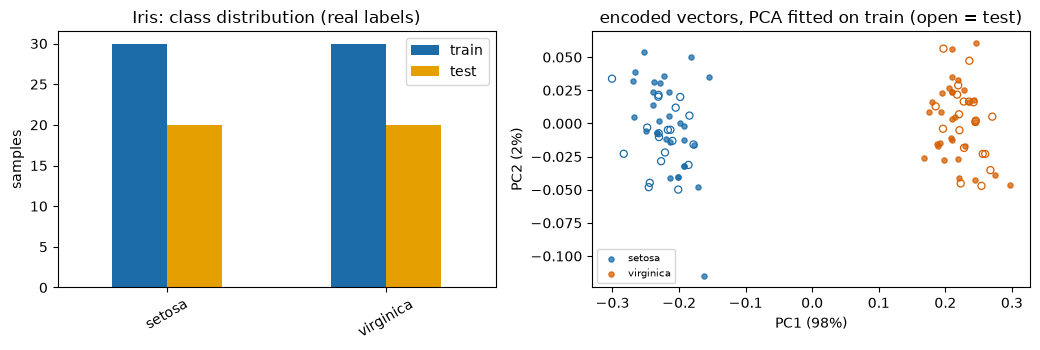

=== BC (UCI Breast Cancer Wisconsin (Original), id 15) ===
shape train / test: (546, 9) (137, 9) | features used: 9 ['Clump_thickness', 'Uniformity_of_cell_size', 'Uniformity_of_cell_shape', 'Marginal_adhesion', 'Single_epithelial_cell_size', 'Bare_nuclei', 'Bland_chromatin', 'Normal_nucleoli', 'Mitoses'] 
original label values and counts (train+test): {2: 444, 4: 239}
model classes: {0: 'benign (2)', 1: 'malignant (4)'} | train counts [355, 191] | test counts [89, 48]


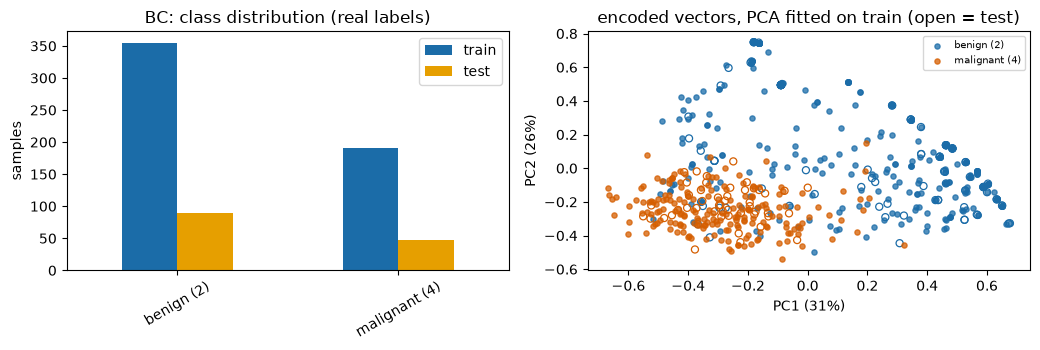

=== PID () ===
shape train / test: (375, 8) (161, 8) | features used: 8 ['preg', 'plas', 'pres', 'skin', 'insu', 'mass', 'pedi', 'age'] 
original label values and counts (train+test): {0: 268, 1: 268}
raw class counts before balancing (0 = negative, 1 = positive): {0: np.int64(500), 1: np.int64(268)} -> balanced to 536 rows
model classes: {0: 'tested_negative', 1: 'tested_positive'} | train counts [187, 188] | test counts [81, 80]


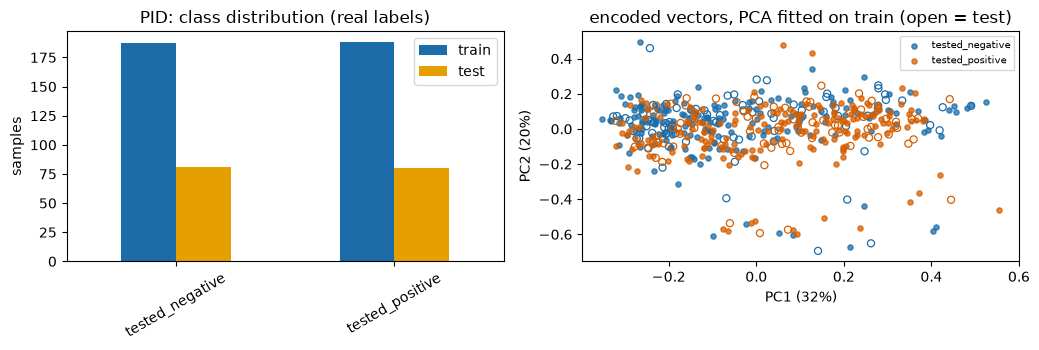

In [5]:
def encoded_vectors(X, n):
    """The vector that the circuit really encodes: zero-padded to 2**n and L2-normalised."""
    d = 2 ** n
    X = np.asarray(X, dtype=float)
    if X.shape[1] < d: X = np.hstack([X, np.zeros((len(X), d - X.shape[1]))])
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

PAL = ["#1b6ca8", "#d55e00", "#009e73", "#cc79a7", "#e69f00", "#56b4e9", "#7b3294", "#555555", "#a6761d", "#e7298a"]

def explore(name, d, show_digits=False):
    Xtr_, ytr_, Xte_, yte_ = d["raw"]
    print(f"=== {name} ({d.get('src', '')}) ===")
    print("shape train / test:", Xtr_.shape, Xte_.shape, "| features used:", len(d["feat"]), d["feat"][:16], "..." if len(d["feat"]) > 16 else "")
    ol = pd.Series(d["orig_labels"]); print("original label values and counts (train+test):", ol.value_counts().sort_index().to_dict())
    if name == "PID": print("raw class counts before balancing (0 = negative, 1 = positive):", dict(enumerate(d["raw_counts"])), "-> balanced to 536 rows")
    print("model classes:", d["classes"], "| train counts", np.bincount(ytr_).tolist(), "| test counts", np.bincount(yte_, minlength=d["K"]).tolist())
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
    cnt = pd.DataFrame({"train": np.bincount(ytr_, minlength=d["K"]), "test": np.bincount(yte_, minlength=d["K"])}, index=[d["classes"][i] for i in range(d["K"])])
    cnt.plot.bar(ax=ax[0], color=["#1b6ca8", "#e69f00"], rot=30); ax[0].set_title(f"{name}: class distribution (real labels)"); ax[0].set_ylabel("samples")
    pca = PCA(2, random_state=SEED).fit(encoded_vectors(Xtr_, d["n"]))
    Ptr, Pte = pca.transform(encoded_vectors(Xtr_, d["n"])), pca.transform(encoded_vectors(Xte_, d["n"]))
    for c in range(d["K"]):
        ax[1].scatter(*Ptr[ytr_ == c].T, s=14, color=PAL[c % 10], alpha=0.75, label=d["classes"][c])
        ax[1].scatter(*Pte[yte_ == c].T, s=26, facecolors="none", edgecolors=PAL[c % 10], linewidths=0.9)
    ax[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax[1].set_title("encoded vectors, PCA fitted on train (open = test)"); ax[1].legend(fontsize=7, ncol=2 if d["K"] > 4 else 1)
    plt.tight_layout(); plt.show()

explore("Iris", DS["Iris"]); explore("BC", DS["BC"]); explore("PID", DS["PID"])

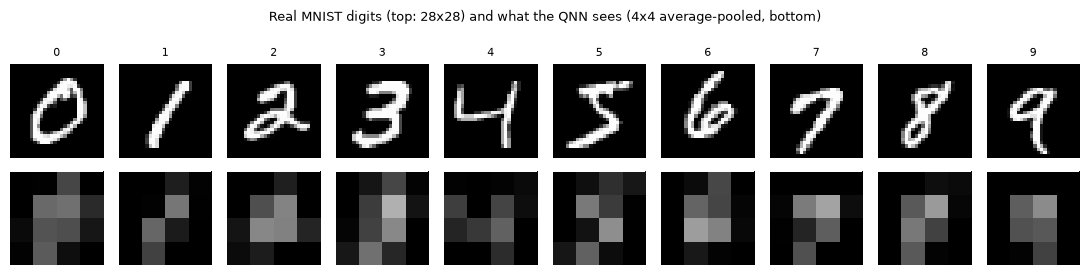

=== MNIST2 () ===
shape train / test: (3000, 16) (1000, 16) | features used: 16 ['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9', 'pixel_10', 'pixel_11', 'pixel_12', 'pixel_13', 'pixel_14', 'pixel_15'] 
original label values and counts (train+test): {1: 2152, 9: 1848}
model classes: {0: 'digit 1', 1: 'digit 9'} | train counts [1622, 1378] | test counts [530, 470]


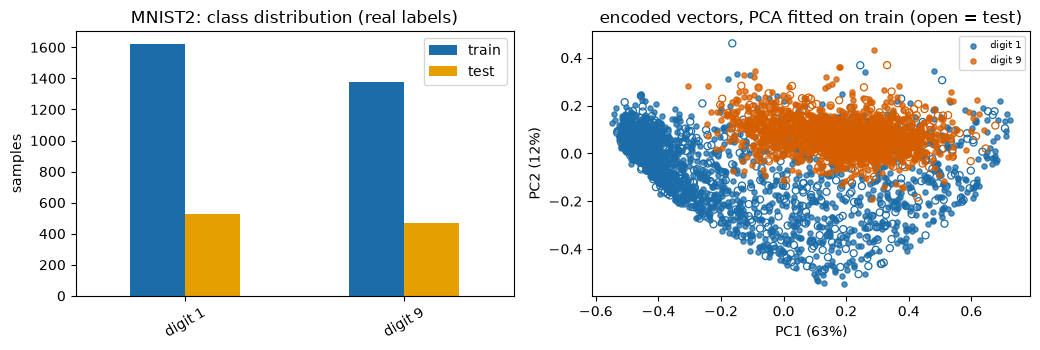

=== MNIST4 () ===
shape train / test: (3000, 16) (1000, 16) | features used: 16 ['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9', 'pixel_10', 'pixel_11', 'pixel_12', 'pixel_13', 'pixel_14', 'pixel_15'] 
original label values and counts (train+test): {1: 1084, 3: 973, 7: 1003, 9: 940}
model classes: {0: 'digit 1', 1: 'digit 9', 2: 'digit 7', 3: 'digit 3'} | train counts [799, 703, 772, 726] | test counts [285, 237, 231, 247]


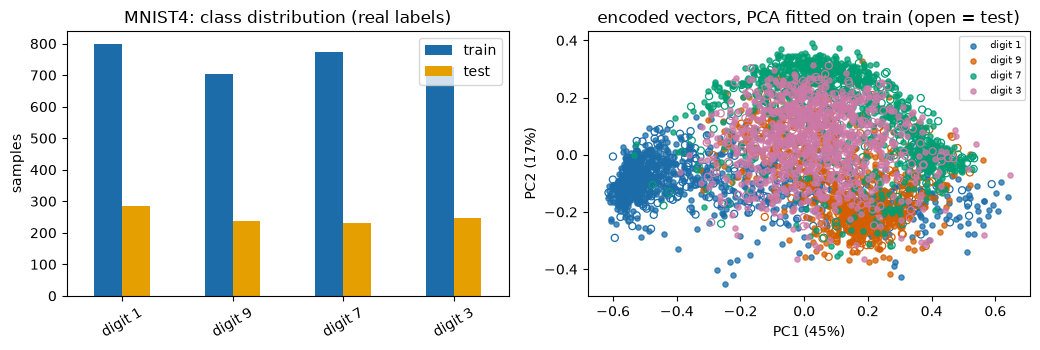

=== MNIST10 () ===
shape train / test: (3000, 16) (1000, 16) | features used: 16 ['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9', 'pixel_10', 'pixel_11', 'pixel_12', 'pixel_13', 'pixel_14', 'pixel_15'] 
original label values and counts (train+test): {0: 387, 1: 418, 2: 401, 3: 421, 4: 382, 5: 357, 6: 390, 7: 420, 8: 425, 9: 399}
model classes: {0: 'digit 0', 1: 'digit 1', 2: 'digit 2', 3: 'digit 3', 4: 'digit 4', 5: 'digit 5', 6: 'digit 6', 7: 'digit 7', 8: 'digit 8', 9: 'digit 9'} | train counts [294, 316, 299, 318, 292, 258, 294, 313, 309, 307] | test counts [93, 102, 102, 103, 90, 99, 96, 107, 116, 92]


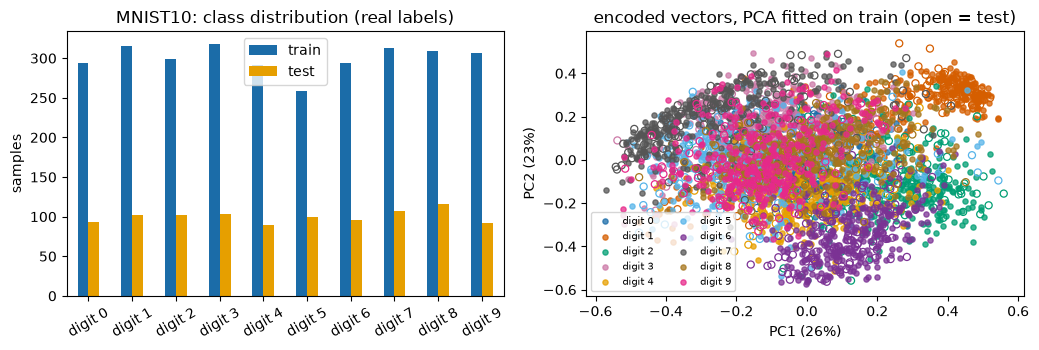

In [6]:
# MNIST: real digits before / after pooling, then the usual summary per task
fig, ax = plt.subplots(2, 10, figsize=(11, 2.9))
for c in range(10):
    i = np.where(MY[:60000] == c)[0][0]
    ax[0, c].imshow(MX[i].reshape(28, 28), cmap="gray"); ax[0, c].axis("off"); ax[0, c].set_title(str(c), fontsize=8)
    ax[1, c].imshow(pool_mnist(MX[i:i + 1], MNIST_SIDE).reshape(MNIST_SIDE, MNIST_SIDE), cmap="gray", vmin=0, vmax=1); ax[1, c].axis("off")
fig.suptitle(f"Real MNIST digits (top: 28x28) and what the QNN sees ({MNIST_SIDE}x{MNIST_SIDE} average-pooled, bottom)", fontsize=9)
plt.tight_layout(); plt.show()
for name in MNIST_TASKS: explore(name, DS[name])

## 3. Quantum Circuit Architecture

The QNN of the paper is *amplitude embedding -> `StronglyEntanglingLayers` -> measurement of the first `m` qubits*. The QNode below is exactly the object that is trained (`default.qubit`),
attacked and evaluated; for noisy runs the same gates run on `default.mixed` and a `DepolarizingChannel(p)` is inserted on **every qubit after every layer** (the paper's Figure 2 shows one channel
`eps_p1` between two unitaries; the exact placement is not given, so this is a `# CHOICE`; for `p = 0` the channels are omitted and the cheaper state-vector device is used).

* Encoding: `AmplitudeEmbedding` of the zero-padded, L2-normalised feature vector (the paper uses the Mottonen decomposition; on a simulator both prepare the same state).
* Layer `l`: `Rot(phi, theta, omega)` (= `Rz Ry Rz`) on each qubit, then a ring of CNOTs `i -> i + r_l (mod n)` with range `r_l = (l mod (n-1)) + 1` (Schuld et al. permute the CNOT pattern per layer).
* Measurement: probabilities of computational basis states of the first `m` qubits; the first `K` outcomes are the classes (for MNIST10, 10 of the 16 outcomes of 4 qubits), renormalised.

In [7]:
RANGES = lambda n, L: [(l % (n - 1)) + 1 for l in range(L)]
_QN = {}
def get_qnode(n, L, m, noisy):
    """The QNN as a PennyLane QNode (torch interface, back-propagation). noisy=True -> density-matrix device + depolarizing channels."""
    key = (n, L, m, noisy)
    if key in _QN: return _QN[key]
    dev = qml.device("default.mixed" if noisy else "default.qubit", wires=n)
    rg = RANGES(n, L)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(xn, w, p):
        qml.AmplitudeEmbedding(xn, wires=range(n), normalize=False)
        for l in range(L):
            qml.StronglyEntanglingLayers(w[l:l + 1], wires=range(n), ranges=[rg[l]])
            if noisy:
                for q in range(n):
                    qml.DepolarizingChannel(p, wires=q)      # CHOICE: a channel on every qubit after every layer
        return qml.probs(wires=list(range(m)))
    _QN[key] = circuit
    return circuit

def pad_norm(x, n):
    """Zero-pad to 2**n and L2-normalise inside the autograd graph (the attack lives in the un-normalised space)."""
    d = 2 ** n
    if x.shape[1] < d: x = torch.cat([x, torch.zeros(x.shape[0], d - x.shape[1], dtype=x.dtype)], 1)
    return x / x.norm(dim=1, keepdim=True).clamp_min(1e-9)

def class_probs(x, w, cfg, p=0.0):
    pr = get_qnode(cfg["n"], cfg["L"], cfg["m"], p > 0)(pad_norm(x, cfg["n"]), w, float(p))[:, :cfg["K"]]
    return pr / pr.sum(1, keepdim=True).clamp_min(1e-12)

def ce(pr, y): return -torch.log(pr[torch.arange(len(y)), y].clamp_min(1e-12)).mean()
def predict(x, w, cfg, p=0.0):
    with torch.no_grad(): return class_probs(x, w, cfg, p).argmax(1)
def accuracy(x, y, w, cfg, p=0.0): return (predict(x, w, cfg, p) == y).double().mean().item()

def grad_x(x, y, w, cfg, p=0.0):
    x = x.clone().requires_grad_(True)
    loss = ce(class_probs(x, w, cfg, p), y) * len(y)
    return torch.autograd.grad(loss, x)[0]

def fgsm(x, y, w, cfg, eps, p=0.0, g=None):
    return x + eps * (grad_x(x, y, w, cfg, p) if g is None else g).sign()

def pgd(x, y, w, cfg, eps, T, p=0.0):
    xa = x.clone()
    for _ in range(T):
        xa = xa + eps / T * grad_x(xa, y, w, cfg, p).sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps)          # projection on the L-infinity ball
    return xa

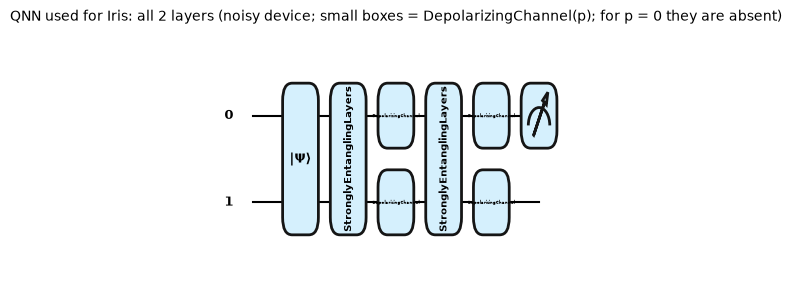

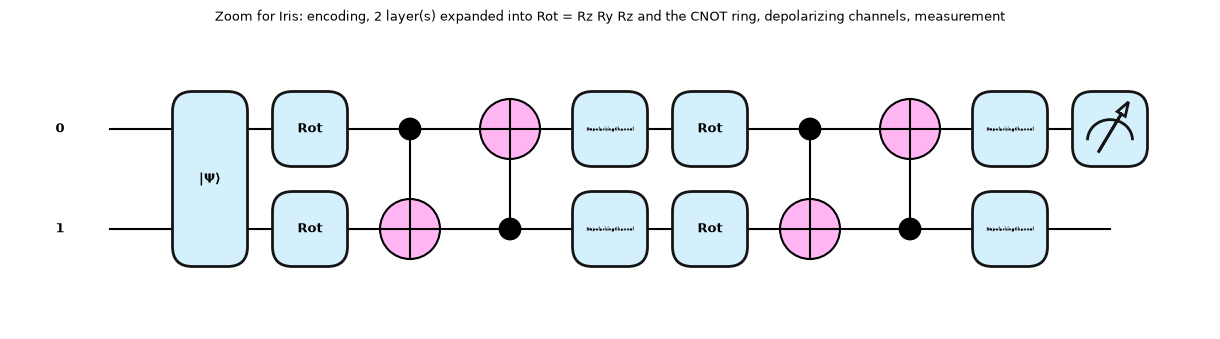

Iris: qubits = 2, layers = 2, measured qubits = 1 (D_meas = 2), trainable parameters = 12 (= 3 x 2 x 2), gates per layer: 6 single-qubit rotations (Rot = Rz Ry Rz) + 2 CNOT with range [1, 1]...
   noise-free circuit depth (device level, gate count by type): 7 {'AmplitudeEmbedding': 1, 'Rot': 4, 'CNOT': 4}
   noisy circuit depth including the 4 depolarizing channels: 9


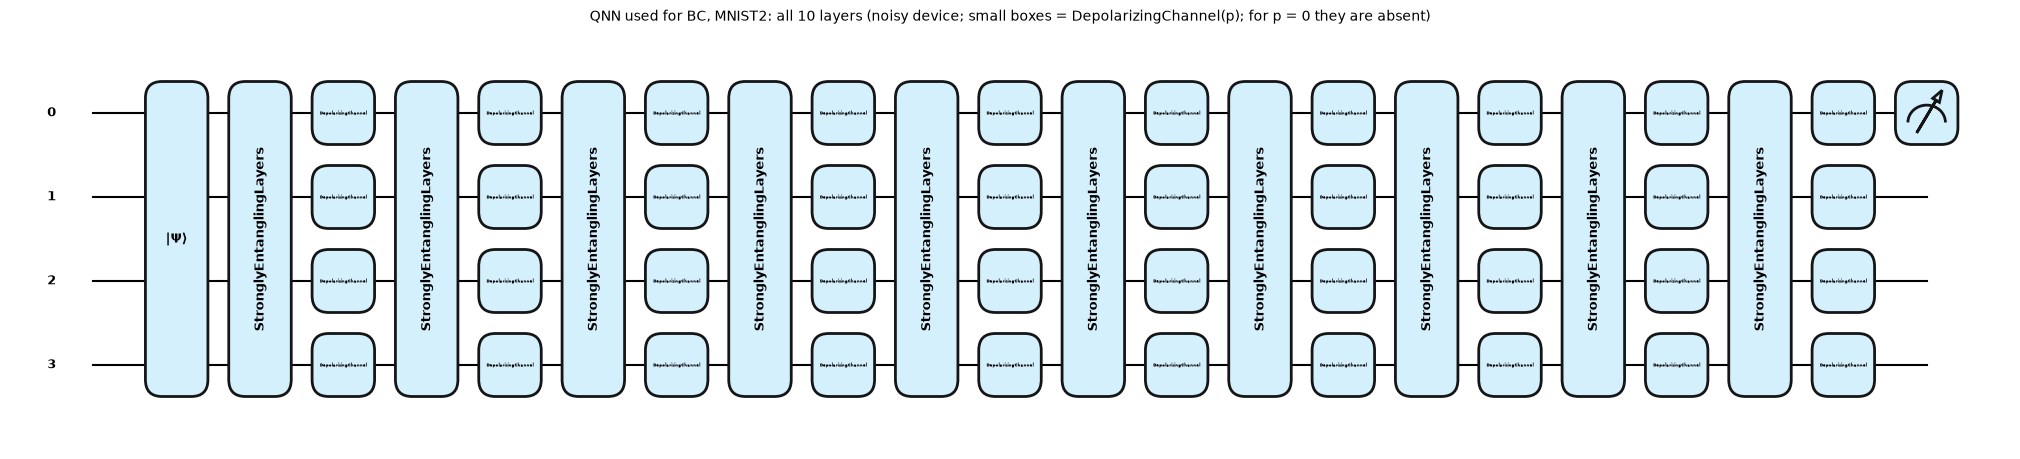

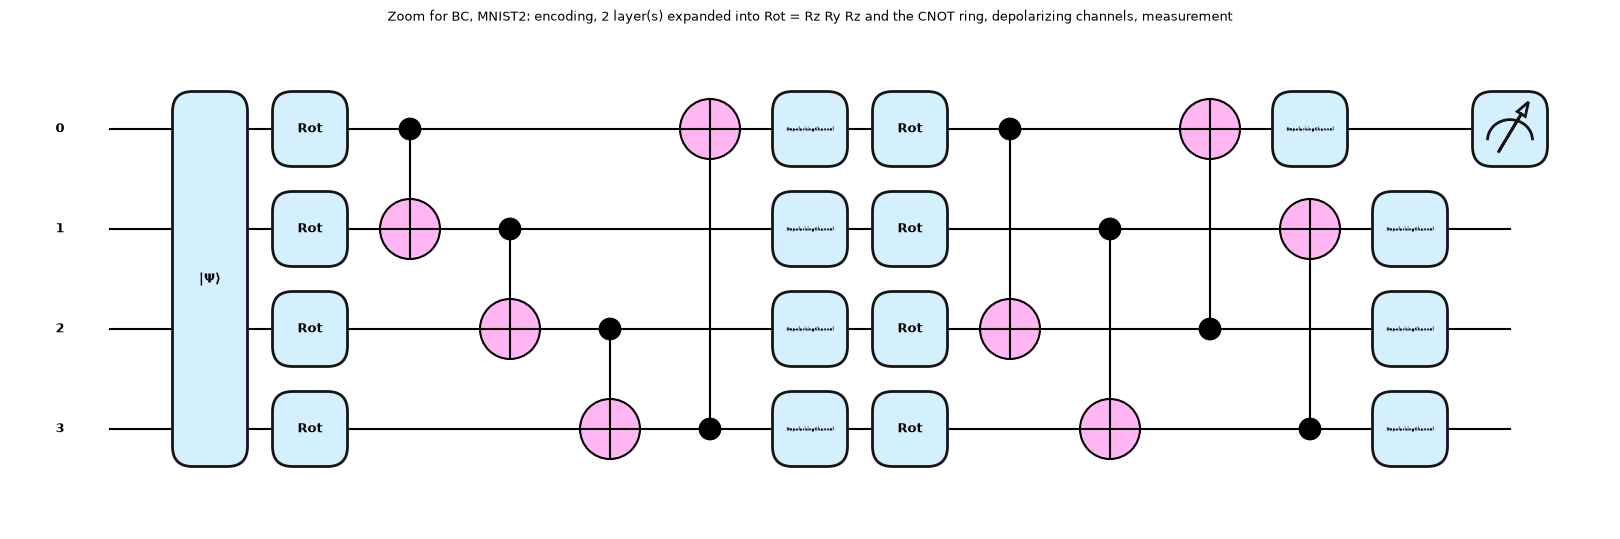

BC, MNIST2: qubits = 4, layers = 10, measured qubits = 1 (D_meas = 2), trainable parameters = 120 (= 3 x 10 x 4), gates per layer: 12 single-qubit rotations (Rot = Rz Ry Rz) + 4 CNOT with range [1, 2, 3, 1]...
   noise-free circuit depth (device level, gate count by type): 42 {'AmplitudeEmbedding': 1, 'Rot': 40, 'CNOT': 40}
   noisy circuit depth including the 40 depolarizing channels: 52


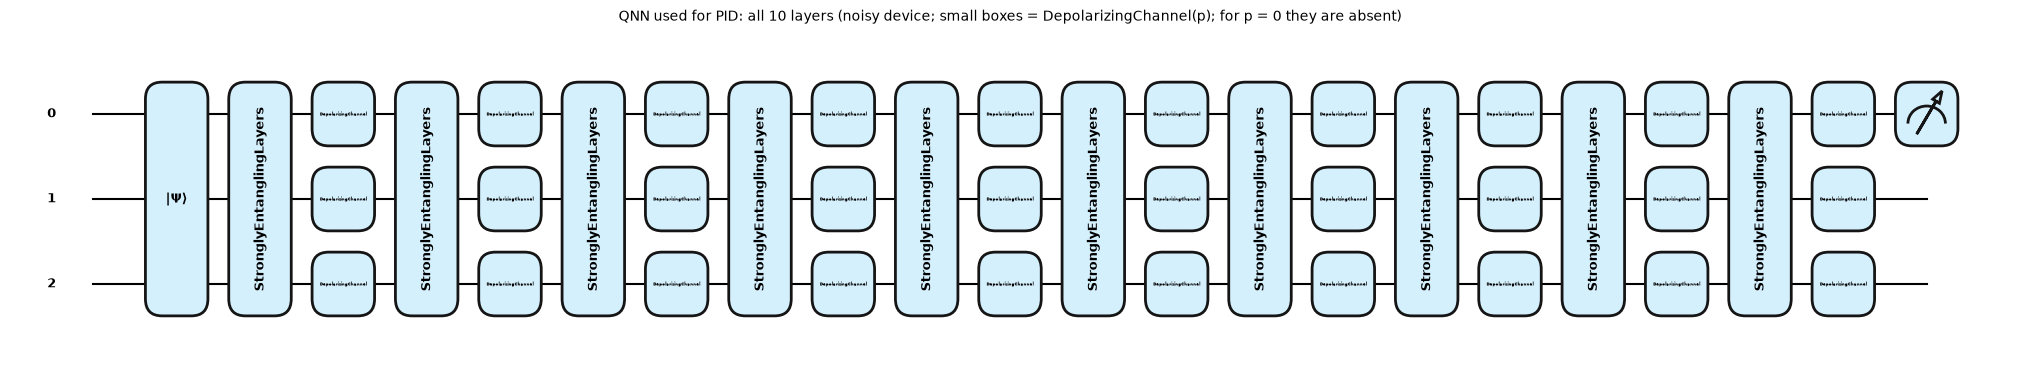

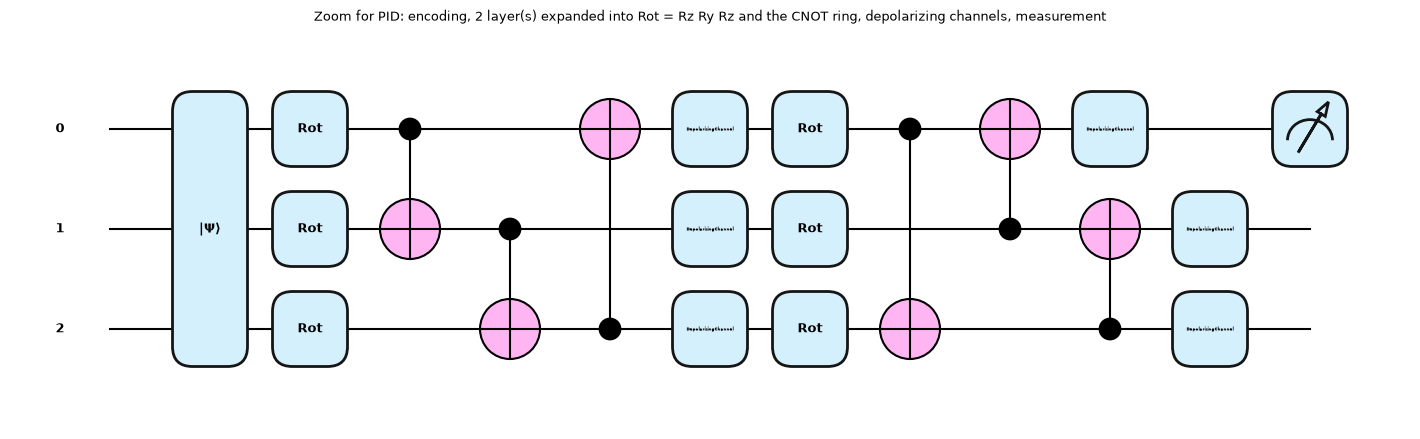

PID: qubits = 3, layers = 10, measured qubits = 1 (D_meas = 2), trainable parameters = 90 (= 3 x 10 x 3), gates per layer: 9 single-qubit rotations (Rot = Rz Ry Rz) + 3 CNOT with range [1, 2, 1, 2]...
   noise-free circuit depth (device level, gate count by type): 41 {'AmplitudeEmbedding': 1, 'Rot': 30, 'CNOT': 30}
   noisy circuit depth including the 30 depolarizing channels: 51


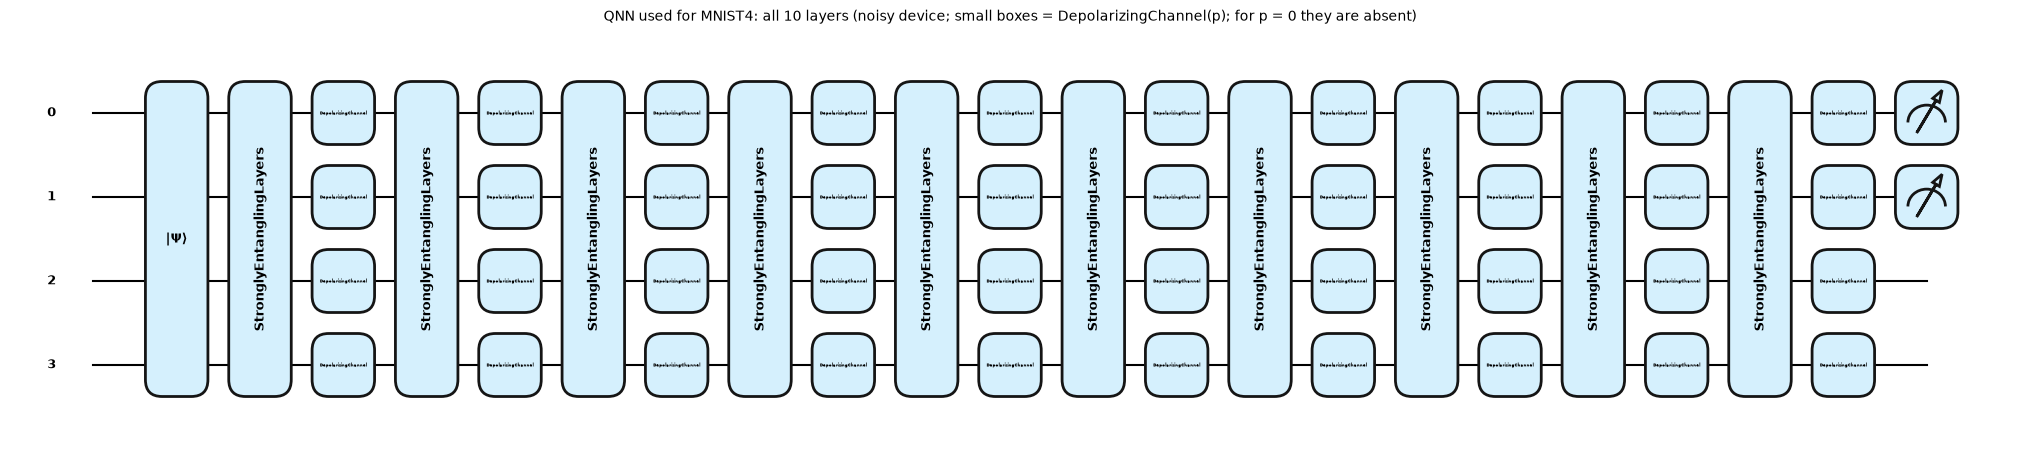

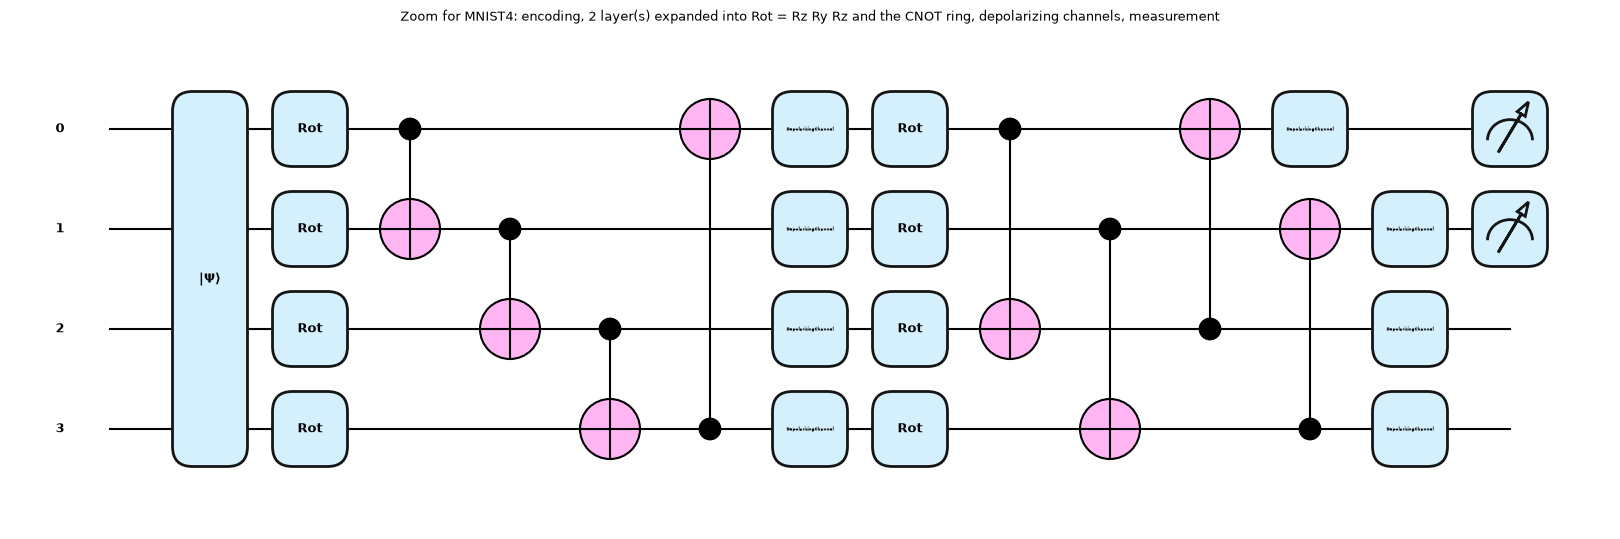

MNIST4: qubits = 4, layers = 10, measured qubits = 2 (D_meas = 4), trainable parameters = 120 (= 3 x 10 x 4), gates per layer: 12 single-qubit rotations (Rot = Rz Ry Rz) + 4 CNOT with range [1, 2, 3, 1]...
   noise-free circuit depth (device level, gate count by type): 42 {'AmplitudeEmbedding': 1, 'Rot': 40, 'CNOT': 40}
   noisy circuit depth including the 40 depolarizing channels: 52


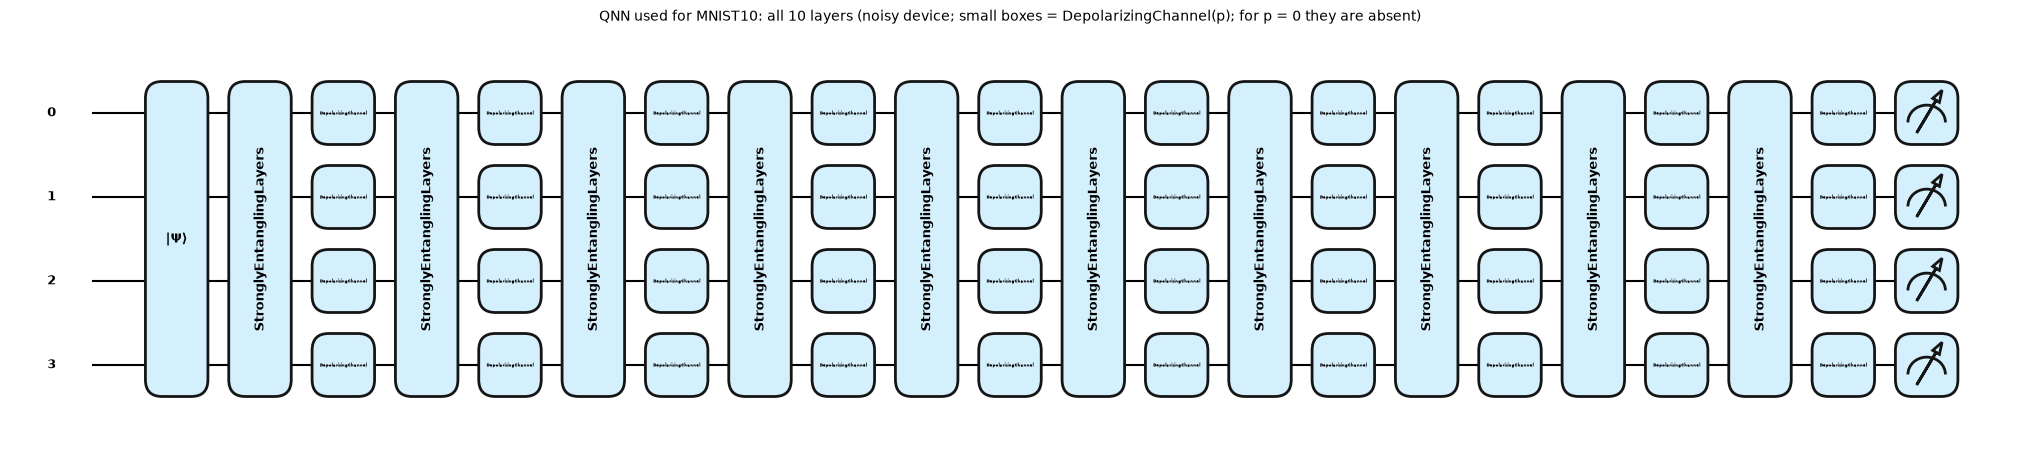

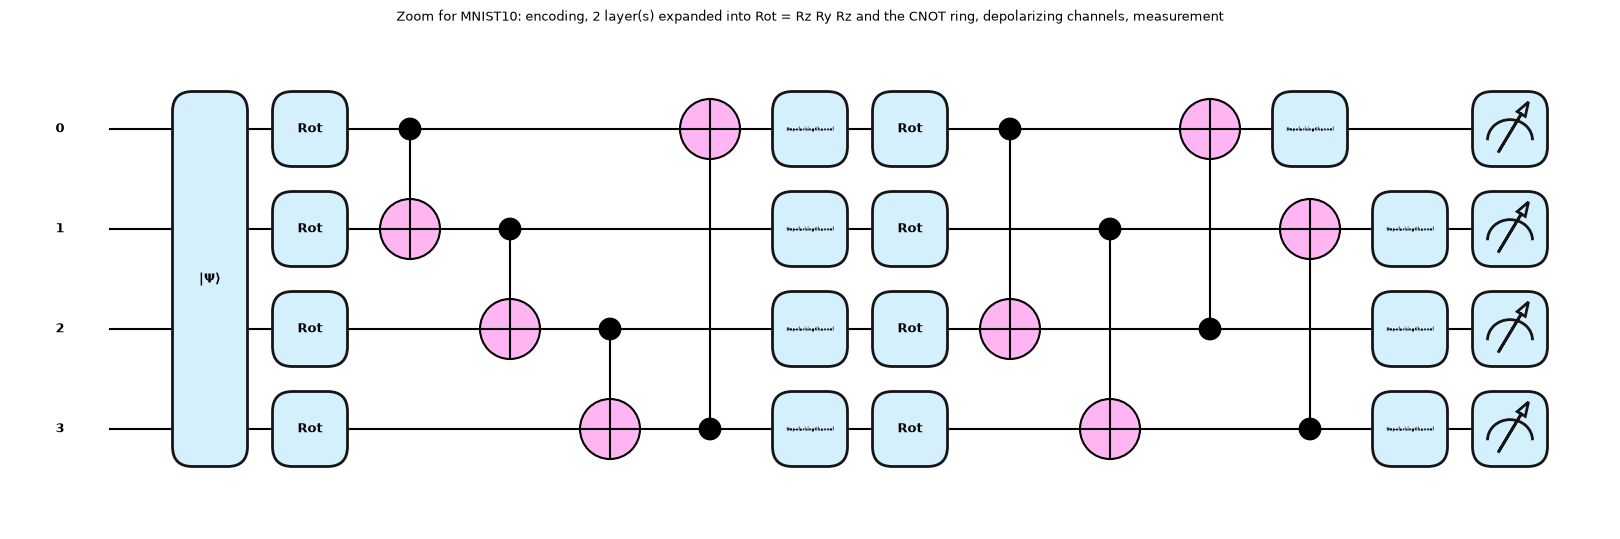

MNIST10: qubits = 4, layers = 10, measured qubits = 4 (D_meas = 16), trainable parameters = 120 (= 3 x 10 x 4), gates per layer: 12 single-qubit rotations (Rot = Rz Ry Rz) + 4 CNOT with range [1, 2, 3, 1]...
   noise-free circuit depth (device level, gate count by type): 42 {'AmplitudeEmbedding': 1, 'Rot': 40, 'CNOT': 40}
   noisy circuit depth including the 40 depolarizing channels: 52


In [8]:
# Draw the circuit that is really executed: one drawing per distinct architecture (n qubits, L layers, m measured qubits).
archs = {}
for k, d in DS.items(): archs.setdefault((d["n"], d["L"], d["m"]), []).append(k)
for (n, L, m), names in archs.items():
    qn = get_qnode(n, L, m, True)
    xn = torch.tensor(encoded_vectors(np.random.default_rng(0).random((1, 2 ** n)), n)[0]); w = torch.zeros(L, n, 3) + 0.1
    fig, ax = qml.draw_mpl(qn, decimals=None, style="pennylane", fontsize=9)(xn, w, 0.1)
    fig.set_size_inches(min(2.0 + 1.35 * L * (n + 1.5), 60) / 3.0, 1.0 + 0.8 * n)
    ax.set_title(f"QNN used for {', '.join(names)}: all {L} layers (noisy device; small boxes = DepolarizingChannel(p); for p = 0 they are absent)", fontsize=10)
    plt.show()
    # zoom: the same QNode factory with the template expanded to its gates (device level), first two layers (all of them for Iris)
    L2 = min(L, 2); qz = get_qnode(n, L2, m, True)
    fig, ax = qml.draw_mpl(qz, level="device", decimals=None, style="pennylane", fontsize=9)(xn, w[:L2], 0.1)
    ax.set_title(f"Zoom for {', '.join(names)}: encoding, {L2} layer(s) expanded into Rot = Rz Ry Rz and the CNOT ring, depolarizing channels, measurement", fontsize=9)
    plt.show()
    res = qml.specs(qn, level="device")(xn, w, 0.1)["resources"]
    print(f"{', '.join(names)}: qubits = {n}, layers = {L}, measured qubits = {m} (D_meas = {2 ** m}), trainable parameters = {w.numel()} (= 3 x {L} x {n}), "
          f"gates per layer: {3 * n} single-qubit rotations (Rot = Rz Ry Rz) + {n} CNOT with range {RANGES(n, L)[:4]}...")
    print("   noise-free circuit depth (device level, gate count by type):", qml.specs(get_qnode(n, L, m, False), level="device")(xn, w, 0.1)["resources"].depth, dict(qml.specs(get_qnode(n, L, m, False), level="device")(xn, w, 0.1)["resources"].gate_types))
    print("   noisy circuit depth including the", n * L, "depolarizing channels:", res.depth)

In [9]:
# Equivalence check: an independent plain-numpy density-matrix simulation (gate matrices from PennyLane, state evolution and Kraus channels written here)
def numpy_probs(xn, w, n, L, m, p):
    rg = RANGES(n, L); psi = np.asarray(xn, dtype=complex); rho = np.outer(psi, psi.conj())
    I2, X, Y, Z = np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1.0, -1.0])
    def embed(op, q): return np.kron(np.kron(np.eye(2 ** q), op), np.eye(2 ** (n - q - 1)))
    for l in range(L):
        U = qml.matrix(qml.StronglyEntanglingLayers(w[l:l + 1].numpy(), wires=range(n), ranges=[rg[l]]), wire_order=range(n))
        rho = U @ rho @ U.conj().T
        for q in range(n):
            K = [np.sqrt(1 - p) * np.eye(2 ** n)] + [np.sqrt(p / 3) * embed(P, q) for P in (X, Y, Z)]
            rho = sum(k @ rho @ k.conj().T for k in K)
    diag = np.real(np.diag(rho)).reshape([2] * n)
    return diag.reshape(2 ** m, -1).sum(1)

for (n, L, m), names in archs.items():
    g = torch.Generator().manual_seed(SEED)
    wt = torch.rand(L, n, 3, generator=g) * 2 * np.pi
    xs = torch.tensor(encoded_vectors(np.random.default_rng(1).random((3, 2 ** n)), n))
    for p in (0.0, 0.1, 0.5, 0.9):
        qn = get_qnode(n, L, m, p > 0)
        out = qn(xs, wt, p).detach().numpy()
        ref = np.array([numpy_probs(x.numpy(), wt, n, L, m, p) for x in xs])
        assert np.allclose(out, ref, atol=1e-8), (names, p, np.abs(out - ref).max())
    # the state-vector and the density-matrix device agree at p = 0
    assert np.allclose(get_qnode(n, L, m, False)(xs, wt, 0.0).detach().numpy(), get_qnode(n, L, m, True)(xs, wt, 0.0).detach().numpy(), atol=1e-8)
    print(f"{names}: PennyLane QNode == numpy density-matrix reference for p in 0, 0.1, 0.5, 0.9 and default.qubit == default.mixed at p = 0  -> OK")

['Iris']: PennyLane QNode == numpy density-matrix reference for p in 0, 0.1, 0.5, 0.9 and default.qubit == default.mixed at p = 0  -> OK


['BC', 'MNIST2']: PennyLane QNode == numpy density-matrix reference for p in 0, 0.1, 0.5, 0.9 and default.qubit == default.mixed at p = 0  -> OK


['PID']: PennyLane QNode == numpy density-matrix reference for p in 0, 0.1, 0.5, 0.9 and default.qubit == default.mixed at p = 0  -> OK


['MNIST4']: PennyLane QNode == numpy density-matrix reference for p in 0, 0.1, 0.5, 0.9 and default.qubit == default.mixed at p = 0  -> OK


['MNIST10']: PennyLane QNode == numpy density-matrix reference for p in 0, 0.1, 0.5, 0.9 and default.qubit == default.mixed at p = 0  -> OK


## 4. Training the vanilla networks and the classical baselines

Adam with cross-entropy (the paper uses negative log-likelihood for MNIST10, which is the same loss on the renormalised class probabilities). The weights are initialised uniformly in `[0, 2 pi)`.
Vanilla models are trained **without noise**; noise is added only when they are evaluated and attacked (as in the paper). A RandomForest and an RBF-SVM are trained on exactly the same encoded vectors
(padded, L2-normalised, train split only).

Iris     QNN test acc 1.0000 +- 0.0000 (3 seeds) | RF 1.0000 | SVC-rbf 1.0000 | train 10 s | final loss 0.343


BC       QNN test acc 0.9319 +- 0.0069 (3 seeds) | RF 0.9635 | SVC-rbf 0.9343 | train 63 s | final loss 0.266


PID      QNN test acc 0.6791 +- 0.0029 (3 seeds) | RF 0.6894 | SVC-rbf 0.6957 | train 32 s | final loss 0.628


MNIST2   QNN test acc 0.9093 +- 0.0178 (3 seeds) | RF 0.9800 | SVC-rbf 0.9780 | train 56 s | final loss 0.394


MNIST4   QNN test acc 0.7907 +- 0.0084 (3 seeds) | RF 0.9130 | SVC-rbf 0.9080 | train 53 s | final loss 0.890


MNIST10  QNN test acc 0.6313 +- 0.0104 (3 seeds) | RF 0.8170 | SVC-rbf 0.7800 | train 56 s | final loss 1.363


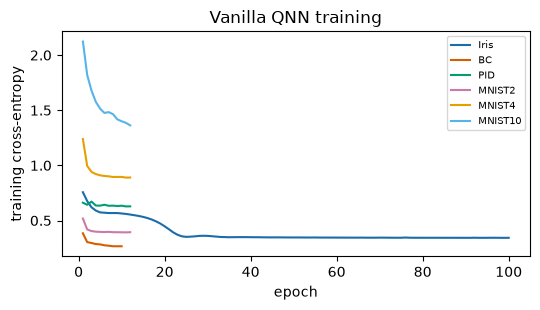

In [10]:
def train(Xtr, ytr, cfg, lr, bs, epochs, seed, mode="vanilla", eps=0.0, sigma=0.0, T=3, thr=None, min_acc=0.0, verbose=False):
    g = torch.Generator().manual_seed(seed)
    w = (torch.rand(cfg["L"], cfg["n"], 3, generator=g) * 2 * np.pi).requires_grad_(True)
    opt = torch.optim.Adam([w], lr=lr); N = len(ytr); hist = []
    for ep in range(epochs):
        perm = torch.randperm(N, generator=g); tot = 0.0
        for i in range(0, N, bs):
            idx = perm[i:i + bs]; xb, yb = Xtr[idx], ytr[idx]
            if mode == "at": xb = pgd(xb, yb, w.detach(), cfg, eps, T, 0.0)                       # adversarial training (PGD examples)
            elif mode == "rs": xb = xb + (torch.rand(xb.shape, generator=g) * 2 - 1) * sigma     # randomized smoothing: U(-sigma, sigma) noise
            loss = ce(class_probs(xb, w, cfg, 0.0), yb)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        hist.append(tot / N)
        if verbose: print(f"   epoch {ep + 1}/{epochs} loss {hist[-1]:.4f}")
        # paper: early stopping at a fixed loss value. CHOICE: only once the clean training accuracy has also reached min_acc (our loss scale differs from the paper's)
        if thr is not None and hist[-1] < thr and accuracy(Xtr, ytr, w.detach(), cfg) >= min_acc: break
    return w.detach(), hist

VAN, ACC, HIST, BASE, TIMES = {}, {}, {}, {}, {}
MODELS = list(DS.keys())
for k in MODELS:
    d = DS[k]; t = time.time(); tp = TRAIN[d["key"]]
    w, h = train(d["Xtr"], d["ytr"], d["cfg"], tp["lr"], tp["bs"], tp["epochs"], SEED)
    TIMES[k] = time.time() - t; VAN[k] = w; HIST[k] = h
    accs = [accuracy(d["Xte"], d["yte"], w, d["cfg"])]
    for s in SEEDS_ACC[1:]:
        w2, _ = train(d["Xtr"], d["ytr"], d["cfg"], tp["lr"], tp["bs"], tp["epochs"], s); accs.append(accuracy(d["Xte"], d["yte"], w2, d["cfg"]))
    ACC[k] = accs
    Ztr, Zte = encoded_vectors(d["Xtr"].numpy(), d["n"]), encoded_vectors(d["Xte"].numpy(), d["n"])
    rf = RandomForestClassifier(200, random_state=SEED).fit(Ztr, d["ytr"].numpy()); sv = SVC(kernel="rbf", random_state=SEED).fit(Ztr, d["ytr"].numpy())
    BASE[k] = (rf.score(Zte, d["yte"].numpy()), sv.score(Zte, d["yte"].numpy()))
    print(f"{k:8s} QNN test acc {np.mean(accs):.4f}" + (f" +- {np.std(accs):.4f} ({len(accs)} seeds)" if len(accs) > 1 else "") + f" | RF {BASE[k][0]:.4f} | SVC-rbf {BASE[k][1]:.4f} | train {TIMES[k]:.0f} s | final loss {h[-1]:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5.5, 3.2))
for i, k in enumerate(MODELS): ax.plot(np.arange(1, len(HIST[k]) + 1), HIST[k], label=k, color=PAL[i])
ax.set_xlabel("epoch"); ax.set_ylabel("training cross-entropy"); ax.set_title("Vanilla QNN training"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 5. Effect of depolarization noise (research question 1, paper Figure 4, Table 2 and Table 3)

For every vanilla model and every noise strength `p` we run the **white-box** attack against the *noisy* model (the attacker differentiates through the density-matrix simulation).
FGSM needs one gradient per `(model, p)` and is then re-scaled for every `eps`; PGD (Iris) re-runs `T` gradient steps per `eps`. "Robustness accuracy" is the paper's Definition 2.
Mean certified trace distance `tau_D` (Eq. 14) is computed for the noise levels of Table 2.

In [11]:
def eps_grid(name): return np.linspace(*(EPS_IRIS if name == "Iris" else EPS_OTHER), N_EPS)
def attack_idx(name): return slice(None) if name == "Iris" else slice(0, N_ATTACK)

def robust_curve(name, w, p, attack=None, T=None):
    """Accuracy of the (noisy, level p) model on adversarial examples crafted against the same noisy model."""
    d = DS[name]; cfg = d["cfg"]; sl = attack_idx(name); X, y = d["Xte"][sl], d["yte"][sl]
    attack = attack or ("pgd" if name == "Iris" else "fgsm"); T = T or T_PGD_IRIS
    accs = []; g = grad_x(X, y, w, cfg, p) if attack == "fgsm" else None
    for e in eps_grid(name):
        if e == 0: xa = X
        elif attack == "fgsm": xa = fgsm(X, y, w, cfg, e, p, g)
        else: xa = pgd(X, y, w, cfg, e, T, p)
        accs.append(accuracy(xa, y, w, cfg, p))
    return np.array(accs)

def tau_D(name, w, p):
    """Mean certified trace distance of Eq. 14 on the whole test set (p is the per-channel noise probability, see the table above)."""
    d = DS[name]; cfg = d["cfg"]
    with torch.no_grad(): pr = class_probs(d["Xte"], w, cfg, p)
    y = d["yte"]; yc = pr[torch.arange(len(y)), y]
    other = pr.clone(); other[torch.arange(len(y)), y] = -1; yk = other.max(1).values.clamp_min(1e-12)
    eps_min = 0.5 * torch.log(yc.clamp_min(1e-12) / yk)
    return (((torch.exp(eps_min) - 1) / (2 ** cfg["m"])) * p / (1 - p)).mean().item()

NOISE, TAU, NT = {}, {}, {}
for k in MODELS:
    t = time.time()
    NOISE[k] = {p: robust_curve(k, VAN[k], p) for p in P_GRID}
    TAU[k] = {p: tau_D(k, VAN[k], p) for p in P_TAU}
    NT[k] = time.time() - t
    print(f"{k:8s} attacked in {NT[k]:.0f} s | tau_D x1e-2 at p=0.1/0.5/0.9: " + " / ".join(f"{100 * TAU[k][p]:.3f}" for p in P_TAU))

Iris     attacked in 142 s | tau_D x1e-2 at p=0.1/0.5/0.9: 2.312 / 2.529 / 8.056


BC       attacked in 68 s | tau_D x1e-2 at p=0.1/0.5/0.9: 0.060 / -0.000 / 0.000


PID      attacked in 25 s | tau_D x1e-2 at p=0.1/0.5/0.9: 0.032 / 0.000 / -0.000


MNIST2   attacked in 72 s | tau_D x1e-2 at p=0.1/0.5/0.9: 0.038 / 0.000 / 0.000


MNIST4   attacked in 92 s | tau_D x1e-2 at p=0.1/0.5/0.9: 0.018 / -0.000 / -0.000


MNIST10  attacked in 87 s | tau_D x1e-2 at p=0.1/0.5/0.9: -0.002 / -0.000 / -0.000


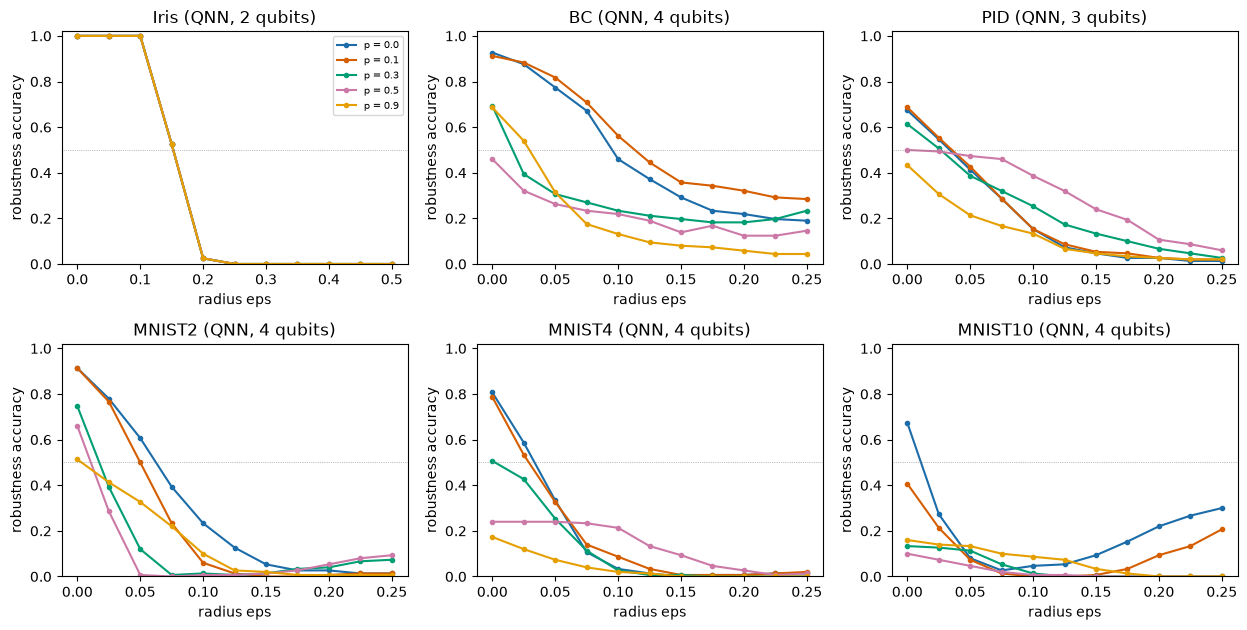


Iris: robustness accuracy (rows: noise p, columns: eps; all 40 test points attacked)
         0  0.05  0.1  0.15   0.2  0.25  0.3  0.35  0.4  0.45  0.5
p=0.0  1.0   1.0  1.0  0.52  0.02   0.0  0.0   0.0  0.0   0.0  0.0
p=0.1  1.0   1.0  1.0  0.52  0.02   0.0  0.0   0.0  0.0   0.0  0.0
p=0.3  1.0   1.0  1.0  0.52  0.02   0.0  0.0   0.0  0.0   0.0  0.0
p=0.5  1.0   1.0  1.0  0.52  0.02   0.0  0.0   0.0  0.0   0.0  0.0
p=0.9  1.0   1.0  1.0  0.52  0.02   0.0  0.0   0.0  0.0   0.0  0.0

BC: robustness accuracy (rows: noise p, columns: eps; 150 test points attacked)
          0  0.025  0.05  0.075   0.1  0.125  0.15  0.175   0.2  0.225  0.25
p=0.0  0.93   0.88  0.77   0.67  0.46   0.37  0.29   0.23  0.22   0.20  0.19
p=0.1  0.91   0.88  0.82   0.71  0.56   0.45  0.36   0.34  0.32   0.29  0.28
p=0.3  0.69   0.39  0.31   0.27  0.23   0.21  0.20   0.18  0.18   0.20  0.23
p=0.5  0.46   0.32  0.26   0.23  0.22   0.19  0.14   0.17  0.12   0.12  0.15
p=0.9  0.69   0.54  0.31   0.18  0.13   0.09  

In [12]:
# Re-draw of the paper's Figure 4: robustness accuracy against eps for every noise level p (vanilla models).
cols = 3; rows = int(np.ceil(len(MODELS) / cols))
fig, axs = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.2 * rows), squeeze=False)
for ax, k in zip(axs.flat, MODELS):
    for i, p in enumerate(P_GRID): ax.plot(eps_grid(k), NOISE[k][p], marker="o", ms=3, color=PAL[i], label=f"p = {p}")
    ax.set_title(f"{k} (QNN, {DS[k]['n']} qubits)"); ax.set_xlabel("radius eps"); ax.set_ylabel("robustness accuracy"); ax.set_ylim(0, 1.02); ax.axhline(0.5, color="grey", lw=0.5, ls=":")
axs.flat[0].legend(fontsize=7)
for ax in list(axs.flat)[len(MODELS):]: ax.axis("off")
plt.tight_layout(); plt.show()

for k in MODELS:
    tab = pd.DataFrame({f"{e:.3g}": [NOISE[k][p][j] for p in P_GRID] for j, e in enumerate(eps_grid(k))}, index=[f"p={p}" for p in P_GRID])
    print(f"\n{k}: robustness accuracy (rows: noise p, columns: eps; {'all 40' if k == 'Iris' else N_ATTACK} test points attacked)"); print(tab.round(2).to_string())

### 5.1 CIFAR2 / Table 3 and the collapse of binary accuracy under strong noise

The paper's Table 3 (CIFAR2, HOG features, 10 qubits, 80 layers) shows accuracy collapsing to 49 % for `p = 0.5` and `0.9`. CIFAR2 is not run here; the same experiment on the
binary tasks we do have (MNIST2, BC, PID) is printed instead.

In [13]:
rows_ = []
for k in [m for m in MODELS if DS[m]["K"] == 2]:
    j = int(np.argmin(np.abs(eps_grid(k) - (0.03 if k != "Iris" else 0.1))))
    rows_.append({"model": k, **{f"p={p}, eps=0": NOISE[k][p][0] for p in P_GRID}, "eps used": round(float(eps_grid(k)[j]), 3), **{f"p={p}, eps": NOISE[k][p][j] for p in P_GRID}})
print("Binary models: accuracy without attack and at a small eps:"); print(pd.DataFrame(rows_).round(3).to_string(index=False))
print("\nPaper Table 3 (CIFAR2, eps = 0 / 0.03): p=0: 82.5/56.0, p=0.1: 79.0/58.0, p=0.5: 49/49, p=0.9: 49/49  (CIFAR2 not run here)")

Binary models: accuracy without attack and at a small eps:
 model  p=0.0, eps=0  p=0.1, eps=0  p=0.3, eps=0  p=0.5, eps=0  p=0.9, eps=0  eps used  p=0.0, eps  p=0.1, eps  p=0.3, eps  p=0.5, eps  p=0.9, eps
  Iris         1.000         1.000         1.000          1.00         1.000     0.100       1.000       1.000       1.000       1.000       1.000
    BC         0.927         0.912         0.693          0.46         0.686     0.025       0.876       0.883       0.394       0.321       0.540
   PID         0.673         0.687         0.613          0.50         0.433     0.025       0.547       0.553       0.507       0.493       0.307
MNIST2         0.913         0.913         0.747          0.66         0.513     0.025       0.780       0.767       0.393       0.287       0.413

Paper Table 3 (CIFAR2, eps = 0 / 0.03): p=0: 82.5/56.0, p=0.1: 79.0/58.0, p=0.5: 49/49, p=0.9: 49/49  (CIFAR2 not run here)


## 6. Adversarial training and randomized smoothing (research question 2, Figures 5 and 6, Table 2)

Defended models are trained with the same architecture and optimiser as the vanilla ones, using PGD adversarial examples (`eps_train` = 0.01, 0.05, 0.09) or uniform noise
(`sigma` = 0.1, 0.5, 0.9), and stop early at the loss thresholds of the paper. They are then attacked **without** noise (research question 2); noise is added on top in Section 7.

In [14]:
DEF = {}   # (dataset, kind, value) -> dict(w, acc, curve, tau, hist)
def run_defence(name, kind, val):
    d = DS[name]; cfg = d["cfg"]; tp = TRAIN[d["key"]]
    if name == "Iris": Xtr, ytr, epochs, T, bs = d["Xtr"], d["ytr"], tp["epochs"], T_PGD_IRIS, tp["bs"]
    else: Xtr, ytr, epochs, T, bs = d["Xtr"][:N_DEF_TRAIN], d["ytr"][:N_DEF_TRAIN], DEF_EPOCHS, T_PGD_TRAIN_MNIST, tp["bs"]
    t = time.time()
    w, h = train(Xtr, ytr, cfg, tp["lr"], bs, epochs, SEED, mode=kind, eps=val if kind == "at" else 0.0, sigma=val if kind == "rs" else 0.0, T=T, thr=EARLY_STOP.get(name), min_acc=0.95 * accuracy(Xtr, ytr, VAN[name], cfg))
    DEF[(name, kind, val)] = dict(w=w, acc=accuracy(d["Xte"], d["yte"], w, cfg), curve=robust_curve(name, w, 0.0), tau={p: tau_D(name, w, p) for p in P_TAU}, hist=h)
    print(f"{name:8s} {kind.upper()} {val:<5} -> test acc {DEF[(name, kind, val)]['acc']:.4f} | epochs run {len(h)} (last loss {h[-1]:.3f}) | {time.time() - t:.0f} s")

for v in AT_EPS_IRIS: run_defence("Iris", "at", v)
for v in RS_SIG_IRIS: run_defence("Iris", "rs", v)
for k in MNIST_TASKS:
    for v in AT_EPS_MNIST: run_defence(k, "at", v)
    for v in RS_SIG_MNIST: run_defence(k, "rs", v)

Iris     AT 0.01  -> test acc 0.9750 | epochs run 12 (last loss 0.575) | 31 s


Iris     AT 0.05  -> test acc 1.0000 | epochs run 18 (last loss 0.560) | 41 s


Iris     AT 0.09  -> test acc 1.0000 | epochs run 19 (last loss 0.591) | 48 s


Iris     RS 0.1   -> test acc 1.0000 | epochs run 12 (last loss 0.553) | 10 s


Iris     RS 0.5   -> test acc 1.0000 | epochs run 13 (last loss 0.512) | 10 s


...

MNIST10  AT 0.05  -> test acc 0.3920 | epochs run 8 (last loss 2.622) | 71 s


MNIST10  AT 0.09  -> test acc 0.3680 | epochs run 8 (last loss 3.554) | 72 s


MNIST10  RS 0.1   -> test acc 0.5810 | epochs run 8 (last loss 1.699) | 31 s


MNIST10  RS 0.5   -> test acc 0.3530 | epochs run 8 (last loss 2.502) | 27 s


MNIST10  RS 0.9   -> test acc 0.1400 | epochs run 8 (last loss 2.754) | 27 s


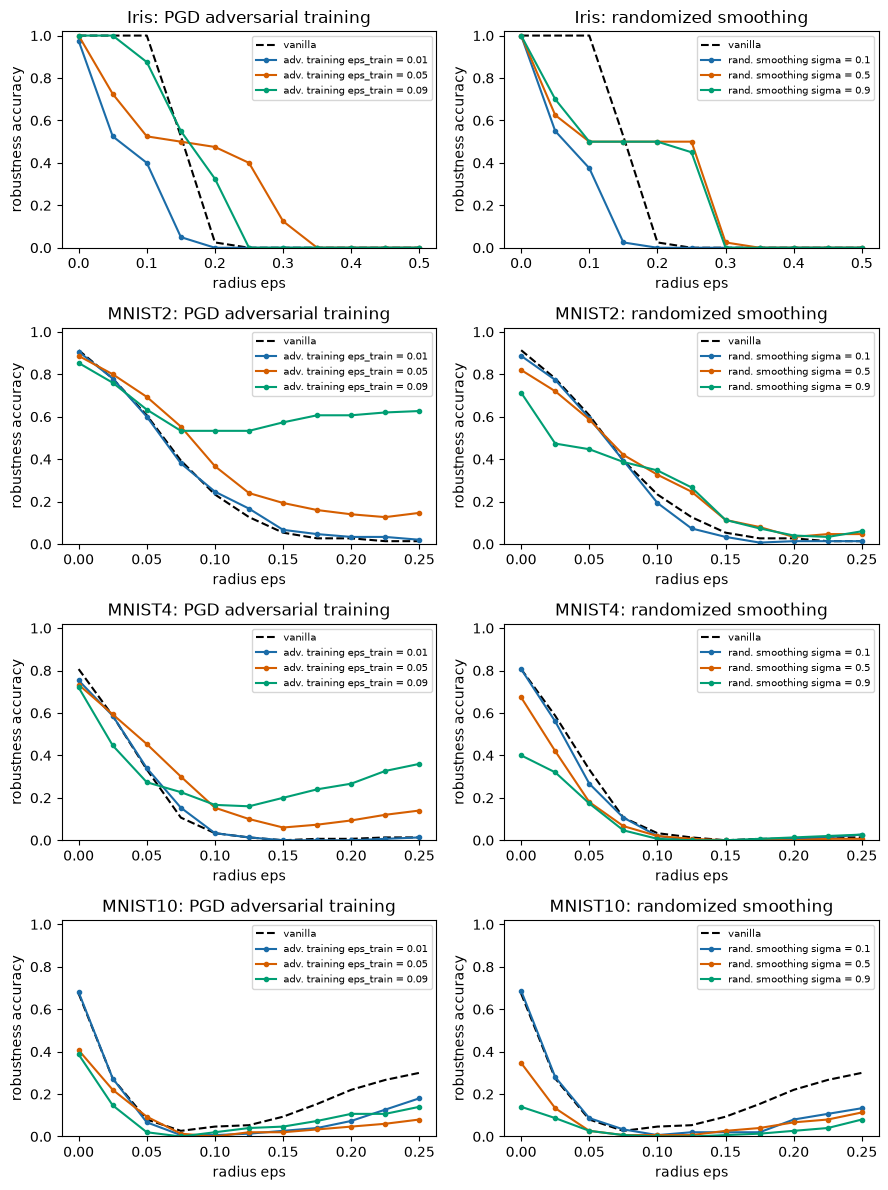

In [15]:
# Re-draw of Figures 5 and 6: robustness accuracy (no noise) of the defended models, vanilla in black.
dsets = ["Iris"] + list(MNIST_TASKS)
fig, axs = plt.subplots(len(dsets), 2, figsize=(9, 3.0 * len(dsets)), squeeze=False)
for r, k in enumerate(dsets):
    for c, (kind, lab, vals) in enumerate((("at", "adv. training eps_train", AT_EPS_IRIS if k == "Iris" else AT_EPS_MNIST), ("rs", "rand. smoothing sigma", RS_SIG_IRIS if k == "Iris" else RS_SIG_MNIST))):
        ax = axs[r, c]; ax.plot(eps_grid(k), NOISE[k][0.0], color="black", ls="--", label="vanilla")
        for i, v in enumerate(vals): ax.plot(eps_grid(k), DEF[(k, kind, v)]["curve"], marker="o", ms=3, color=PAL[i], label=f"{lab} = {v}")
        ax.set_title(f"{k}: {'PGD adversarial training' if kind == 'at' else 'randomized smoothing'}"); ax.set_xlabel("radius eps"); ax.set_ylabel("robustness accuracy"); ax.set_ylim(0, 1.02); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Depolarization noise on top of adversarial training / smoothing (research question 3, Figure 7)

The paper does this for MNIST2 only: the defended models are attacked while the depolarizing noise `p` is switched on.

MNIST2 AT 0.01: noisy attacks done in 39 s


MNIST2 AT 0.05: noisy attacks done in 36 s


MNIST2 AT 0.09: noisy attacks done in 32 s


MNIST2 RS 0.1: noisy attacks done in 34 s


MNIST2 RS 0.5: noisy attacks done in 31 s


MNIST2 RS 0.9: noisy attacks done in 31 s


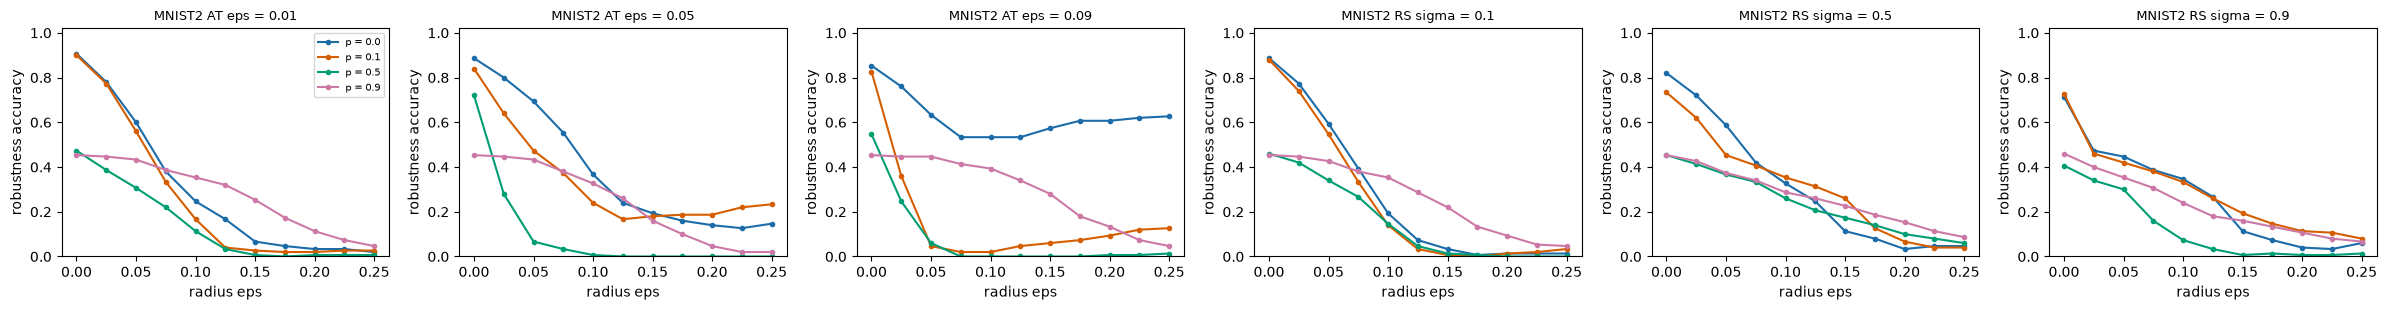

In [16]:
BLEND = {}
k = "MNIST2"
blend_models = [("at", v) for v in AT_EPS_MNIST] + [("rs", v) for v in RS_SIG_MNIST]
p_blend = [p for p in P_GRID if p in (0.0, 0.1, 0.5, 0.9)]
for kind, v in blend_models:
    t = time.time(); w = DEF[(k, kind, v)]["w"]
    BLEND[(kind, v)] = {p: (DEF[(k, kind, v)]["curve"] if p == 0 else robust_curve(k, w, p)) for p in p_blend}
    print(f"MNIST2 {kind.upper()} {v}: noisy attacks done in {time.time() - t:.0f} s")
fig, axs = plt.subplots(1, len(blend_models), figsize=(4.0 * len(blend_models), 3.2), squeeze=False)
for ax, (kind, v) in zip(axs[0], blend_models):
    for i, p in enumerate(p_blend): ax.plot(eps_grid(k), BLEND[(kind, v)][p], marker="o", ms=3, color=PAL[i], label=f"p = {p}")
    ax.set_title(f"MNIST2 {'AT eps' if kind == 'at' else 'RS sigma'} = {v}", fontsize=9); ax.set_xlabel("radius eps"); ax.set_ylabel("robustness accuracy"); ax.set_ylim(0, 1.02)
axs[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 7.1 Extra (full run only): the same MNIST2 task on 6 qubits

The paper uses 16x16 images on 8 qubits. With 8x8 images (6 qubits) the vanilla accuracy can be compared with the paper's 99.61 % at a cost of a few minutes.

In [17]:
if not FAST_MODE:
    t = time.time()
    (xt, yt_, _, _), (xe, ye, _, _) = make_mnist([1, 9], 8, 1500, 300)
    cfg6 = dict(n=6, L=N_LAYERS["MNIST"], m=1, K=2)
    w6, h6 = train(torch.tensor(xt), torch.tensor(yt_), cfg6, 0.01, 128, 10, SEED)
    ACC6 = accuracy(torch.tensor(xe), torch.tensor(ye), w6, cfg6)
    print(f"MNIST2, 8x8 images, 6 qubits, {cfg6['L']} layers: test accuracy {ACC6:.4f} (300 test images), {time.time() - t:.0f} s")

MNIST2, 8x8 images, 6 qubits, 10 layers: test accuracy 0.9933 (300 test images), 56 s


## 8. Side-by-side comparison with the paper

In [18]:
PAPER_ACC = {"PID": 67.08, "BC": 91.24, "Iris": 100.0, "MNIST2": 99.61, "MNIST4": 90.44, "MNIST10": 80.00}
PAPER_TAU = {"PID": [0.449, 0.443, 0.055], "BC": [6.210, 5.189, 0.926], "Iris": [4.176, 5.960, 1.092], "MNIST2": [2.429, 0.150, 0.006],
             "MNIST4": [1.035, 0.042, -0.007], "MNIST10": [0.205, -0.012, -0.007]}
PAPER_DEF = {  # (dataset, kind, value) -> (test accuracy %, [tau_D x1e-2 at p = 0.1, 0.5, 0.9])
    ("Iris", "at", 0.01): (100.0, [2.823, 5.215, 1.291]), ("Iris", "at", 0.05): (100.0, [2.811, 5.184, 1.276]), ("Iris", "at", 0.09): (100.0, [2.774, 5.100, 1.254]),
    ("Iris", "rs", 0.1): (100.0, [2.824, 5.181, 1.273]), ("Iris", "rs", 0.5): (97.5, [2.661, 4.412, 1.029]), ("Iris", "rs", 0.9): (70.0, [2.375, 3.502, 0.723]),
    ("MNIST2", "at", 0.01): (99.61, [2.366, 0.135, 0.003]), ("MNIST2", "at", 0.05): (99.61, [2.372, 0.127, 0.001]), ("MNIST2", "at", 0.09): (99.21, [2.392, 0.123, 0.002]),
    ("MNIST2", "rs", 0.1): (99.61, [2.369, 0.124, 0.001]), ("MNIST2", "rs", 0.5): (99.61, [2.378, 0.116, -0.003]), ("MNIST2", "rs", 0.9): (99.61, [2.253, 0.111, 0.002]),
    ("MNIST4", "at", 0.01): (90.64, [0.997, 0.034, -0.006]), ("MNIST4", "at", 0.05): (90.64, [0.995, 0.044, -0.003]), ("MNIST4", "at", 0.09): (90.24, [1.000, 0.037, -0.005]),
    ("MNIST4", "rs", 0.1): (91.24, [0.988, 0.048, -0.004]), ("MNIST4", "rs", 0.5): (91.04, [0.988, 0.047, -0.003]), ("MNIST4", "rs", 0.9): (91.43, [0.916, 0.050, -0.003]),
    ("MNIST10", "at", 0.01): (80.50, [0.172, -0.049, -0.014]), ("MNIST10", "at", 0.05): (80.08, [0.173, -0.049, -0.015]), ("MNIST10", "at", 0.09): (81.75, [0.164, -0.030, -0.011]),
    ("MNIST10", "rs", 0.1): (79.50, [0.180, -0.062, -0.017]), ("MNIST10", "rs", 0.5): (76.17, [0.174, -0.053, -0.014]), ("MNIST10", "rs", 0.9): (71.91, [0.167, -0.013, -0.006]),
}
def acc_verdict(nb, paper, tol=2.0):
    gap = nb - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{gap:.1f} pts)" if gap > 0 else f"not reached ({gap:.1f} pts)")
def tau_verdict(nb, paper):
    if np.sign(nb) != np.sign(paper) and abs(paper) > 0.01: return "not reached (sign differs)"
    if abs(paper) <= 0.01 and abs(nb) <= 0.02: return "reproduced (both ~0)"
    r = nb / paper if paper else np.inf
    return f"reproduced (x{r:.2f})" if 0.5 <= r <= 2 else f"not reached (x{r:.2f})"

rows = []
for k in MODELS:
    rows.append({"item": f"{k} vanilla test accuracy (%)", "paper": PAPER_ACC[k], "notebook": round(100 * np.mean(ACC[k]), 2), "verdict": acc_verdict(100 * np.mean(ACC[k]), PAPER_ACC[k])})
    for j, p in enumerate(P_TAU):
        rows.append({"item": f"{k} vanilla tau_D x1e-2, p={p}", "paper": PAPER_TAU[k][j], "notebook": round(100 * TAU[k][p], 3), "verdict": tau_verdict(100 * TAU[k][p], PAPER_TAU[k][j])})
for (k, kind, v), r in DEF.items():
    pa, pt = PAPER_DEF[(k, kind, v)]
    rows.append({"item": f"{k} {kind.upper()} {v} test accuracy (%)", "paper": pa, "notebook": round(100 * r["acc"], 2), "verdict": acc_verdict(100 * r["acc"], pa)})
    for j, p in enumerate(P_TAU):
        rows.append({"item": f"{k} {kind.upper()} {v} tau_D x1e-2, p={p}", "paper": pt[j], "notebook": round(100 * r["tau"][p], 3), "verdict": tau_verdict(100 * r["tau"][p], pt[j])})
if "ACC6" in globals():
    rows.append({"item": "MNIST2 (8x8 images, 6 qubits) vanilla test accuracy (%)", "paper": PAPER_ACC["MNIST2"], "notebook": round(100 * ACC6, 2), "verdict": acc_verdict(100 * ACC6, PAPER_ACC["MNIST2"])})
rows.append({"item": "CIFAR2 accuracy per p (Table 3), tau_D (Table 2)", "paper": "82.5 / 79.0 / 49 / 49", "notebook": "not run", "verdict": "cannot be checked"})
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 200, "display.max_rows", 400)
print(CMP.to_string(index=False))
print("\nSummary of numeric verdicts:"); print(CMP.verdict.str.split(" ").str[0].value_counts().to_string())

                                                   item                 paper notebook                    verdict
                         Iris vanilla test accuracy (%)                 100.0    100.0                 reproduced
                        Iris vanilla tau_D x1e-2, p=0.1                 4.176    2.312         reproduced (x0.55)
                        Iris vanilla tau_D x1e-2, p=0.5                  5.96    2.529        not reached (x0.42)
                        Iris vanilla tau_D x1e-2, p=0.9                 1.092    8.056        not reached (x7.38)
                           BC vanilla test accuracy (%)                 91.24    93.19                 reproduced
                          BC vanilla tau_D x1e-2, p=0.1                  6.21     0.06        not reached (x0.01)
                          BC vanilla tau_D x1e-2, p=0.5                 5.189     -0.0 not reached (sign differs)
                          BC vanilla tau_D x1e-2, p=0.9                 0.926      0.0  

In [19]:
# Qualitative claims of the paper, each checked on our curves. "gain" = robustness accuracy with noise (or defence) minus the vanilla noise-free curve.
claims = []
def claim(text, ok, detail): claims.append({"claim": text, "verdict": "reproduced" if ok else "not reached here", "evidence": detail})

# C1 noise gives no robustness on the multi-class / image models (paper: MNIST2, MNIST4, MNIST10, CIFAR2)
for k in [m for m in MODELS if m.startswith("MNIST")]:
    gains = [(NOISE[k][p] - NOISE[k][0.0]).max() for p in P_GRID if p > 0]
    claim(f"noise does not improve adversarial accuracy on {k}", max(gains) <= TOL_ADV, f"max gain over all p, eps = {max(gains):+.3f}")
# C2 binary small sets: noise helps only for large eps and when the classifier is near / below 50 % (Fig. 4 a-c)
for k in ["Iris", "BC", "PID"]:
    best = (-1, None)
    for p in P_GRID:
        if p == 0: continue
        gain = NOISE[k][p] - NOISE[k][0.0]
        for j in np.where(gain > TOL_ADV)[0]:
            if gain[j] > best[0]: best = (gain[j], (p, float(eps_grid(k)[j]), float(NOISE[k][0.0][j])))
    if best[1] is None: claim(f"{k}: noise helps only at large eps, near/below 50 % accuracy", False, f"noise never raised robustness accuracy by more than {TOL_ADV:.2f}")
    else: claim(f"{k}: noise helps only at large eps, near/below 50 % accuracy", best[1][2] <= 0.55, f"largest gain {best[0]:+.2f} at p={best[1][0]}, eps={best[1][1]:.3g}, where the noise-free accuracy is {best[1][2]:.2f}")
# C3 strong noise drives binary accuracy to chance (paper: CIFAR2 49 % at p = 0.5 and 0.9)
for k in [m for m in MODELS if DS[m]["K"] == 2]:
    a5, a9 = NOISE[k][0.5][0], NOISE[k][0.9][0]
    claim(f"{k}: p = 0.5 and 0.9 reduce clean accuracy to about chance (paper's CIFAR2 analogue, 49 %)", max(a5, a9) <= 0.75 and a5 < NOISE[k][0.0][0] - 0.1, f"clean accuracy p=0: {NOISE[k][0.0][0]:.2f}, p=0.5: {a5:.2f}, p=0.9: {a9:.2f}")
# C4 accuracy and robustness fall with the number of classes
ms = [m for m in MODELS if m.startswith("MNIST")]
if len(ms) > 1:
    a = [np.mean(ACC[m]) for m in ms]; r = [NOISE[m][0.0].mean() for m in ms]
    claim("clean accuracy decreases with the number of classes (MNIST2 > MNIST4 > ...)", all(np.diff(a) < 0), "accuracies " + ", ".join(f"{m} {x:.3f}" for m, x in zip(ms, a)))
    claim("mean robustness accuracy (noise-free attack) decreases with the number of classes", all(np.diff(r) < 0), "mean over eps grid " + ", ".join(f"{m} {x:.3f}" for m, x in zip(ms, r)))
# C5 certified distance negative for the multi-class models at p >= 0.5
for k in [m for m in MODELS if DS[m]["K"] > 2]:
    claim(f"{k}: mean certified distance is non-positive-ish at p = 0.5 and 0.9 (paper: negative / ~0)", all(100 * TAU[k][p] < 0.05 for p in (0.5, 0.9)), f"tau_D x1e-2 at p=0.5/0.9: {100 * TAU[k][0.5]:.3f} / {100 * TAU[k][0.9]:.3f}")
# C6 adversarial training has no influence on Iris
va = NOISE["Iris"][0.0]
dif = max(np.abs(DEF[("Iris", "at", v)]["curve"] - va).mean() for v in AT_EPS_IRIS)
claim("Iris: PGD adversarial training has no influence at these eps_train", dif <= TOL_ADV, f"largest mean |AT - vanilla| over the eps grid = {dif:.3f}")
# C7 Iris randomized smoothing: large sigma falls faster initially but stays higher for large eps
lo, hi = DEF[("Iris", "rs", 0.1)]["curve"], DEF[("Iris", "rs", 0.9)]["curve"]
ini = int(np.argmin(np.abs(eps_grid("Iris") - 0.1)))
claim("Iris: sigma = 0.9 smoothing drops faster initially but stays higher for large eps than sigma = 0.1", hi[ini] < lo[ini] and hi[-1] > lo[-1],
      f"eps={eps_grid('Iris')[ini]:.2f}: {hi[ini]:.2f} vs {lo[ini]:.2f}; eps={eps_grid('Iris')[-1]:.2f}: {hi[-1]:.2f} vs {lo[-1]:.2f}")
# C8 neither AT nor RS helps on MNIST
for k in MNIST_TASKS:
    g = max((DEF[(k, kind, v)]["curve"] - NOISE[k][0.0]).mean() for kind, vals in (("at", AT_EPS_MNIST), ("rs", RS_SIG_MNIST)) for v in vals)
    claim(f"{k}: neither adversarial training nor randomized smoothing gives a clear robustness gain", g <= TOL_ADV, f"largest mean gain over the eps grid = {g:+.3f}")
# C9 noise on top of adversarial training does not help on MNIST2
g = max((BLEND[key][p] - BLEND[key][0.0]).max() for key in BLEND for p in p_blend if p > 0)
claim("MNIST2: adding depolarizing noise on top of AT / RS does not improve robustness", g <= TOL_ADV, f"max gain over all defended models, p, eps = {g:+.3f}")
CL = pd.DataFrame(claims); print(CL.to_string(index=False))
print("\nRuntime of the whole notebook: %.1f min" % ((time.time() - T0) / 60))

                                                                                             claim          verdict                                                                      evidence
                                             noise does not improve adversarial accuracy on MNIST2 not reached here                                             max gain over all p, eps = +0.080
                                             noise does not improve adversarial accuracy on MNIST4 not reached here                                             max gain over all p, eps = +0.180
                                            noise does not improve adversarial accuracy on MNIST10 not reached here                                             max gain over all p, eps = +0.073
                                     Iris: noise helps only at large eps, near/below 50 % accuracy not reached here                      noise never raised robustness accuracy by more than 0.06
                              

In [20]:
# Baselines next to the QNNs, and the architecture size.
tb = pd.DataFrame({"QNN (ours)": {k: np.mean(ACC[k]) for k in MODELS}, "RandomForest": {k: BASE[k][0] for k in MODELS}, "SVC rbf": {k: BASE[k][1] for k in MODELS},
                   "paper QNN": {k: PAPER_ACC[k] / 100 for k in MODELS}, "qubits": {k: DS[k]["n"] for k in MODELS}, "layers": {k: DS[k]["L"] for k in MODELS}})
print("Clean test accuracy on identical inputs:"); print(tb.round(4).to_string())

Clean test accuracy on identical inputs:
         QNN (ours)  RandomForest  SVC rbf  paper QNN  qubits  layers
Iris         1.0000        1.0000   1.0000     1.0000       2       2
BC           0.9319        0.9635   0.9343     0.9124       4      10
PID          0.6791        0.6894   0.6957     0.6708       3      10
MNIST2       0.9093        0.9800   0.9780     0.9961       4      10
MNIST4       0.7907        0.9130   0.9080     0.9044       4      10
MNIST10      0.6313        0.8170   0.7800     0.8000       4      10


## 9. Reading the paper critically

* **What is solid.** The core observation is robust and reproducible: with the noise acting between layers, strong depolarization shrinks the signal in the measured qubits until the classifier is at chance, and the
  small robustness gains it brings in the binary tasks show up only after the attack has already pushed accuracy to chance. The qualitative picture (Fig. 4) does not depend on the exact depth or on the number of qubits.
* **The noise model is under-specified.** "Multiple depolarizing channels" with `p = 1 - prod(1 - p_i)` is not enough to reproduce the numbers: how many channels, on which qubits, and what `p` means in Eq. 14 all change
  the contraction of the Bloch vector (a channel of strength `p` shrinks it by `1 - 4p/3` per application, so `p = 0.9` even flips its sign). Two groups can both claim to follow the paper and measure different curves.
* **Deterministic, noise-free-trained models.** The vanilla networks never see noise during training, and `p` is a post-hoc knob. A network trained *with* the noise could behave differently.
* **The certified distance is a bound on the trace distance, but the attack is in feature space.** Because MNIST is normalised only inside the encoder, the comparison of `tau_D` with `eps` is, as the authors admit, difficult; and the
  bound is an upper bound that says nothing when the classifier is wrong (negative values), so the multi-class tables mostly measure accuracy.
* **Weak attacks.** FGSM (and PGD with 3 steps for training) is the weakest white-box attack; no gradient-masking check is made. Noise-aware FGSM through a density-matrix simulator is a fair white-box attack, but a
  shot-noise or finite-sampling attacker is not studied.
* **Small, easy data.** Iris (setosa vs virginica) is linearly separable, PID tops out near 70 %, and MNIST is reduced to tiny images; the multi-class claim rests on a model that is under-trained
  (accuracy drops by 10 points per extra class partly because the ansatz is shared and small).
* **Our deviations matter.** We use 4 qubits and 10 layers for the image tasks instead of 8 qubits and 40 layers, a different learning rate and fewer epochs; clean accuracies are therefore lower for MNIST, and absolute
  `tau_D` values scale with the (unknown) noise placement. Only the qualitative claims are expected to transfer.

## 10. Exercises

1. **Noise placement.** Move the depolarizing channels to (a) only after the last layer and (b) only on the measured qubits. Does the accuracy still collapse for `p >= 0.5`? Explain with the Bloch-vector shrink factor `1 - 4p/3`.
2. **Noise-aware training.** Train BC with `p = 0.1` channels switched on during training (use `get_qnode(..., noisy=True)` in `train`) and compare its robustness curves with the vanilla network at `p = 0.1`.
3. **Stronger attack.** Replace FGSM by PGD with 10 steps for MNIST2. Does the "noise never helps" conclusion survive? What does the gap between FGSM and PGD say about gradient masking by noise?
4. **Depth.** Re-run the BC experiment with `N_LAYERS["BC"] = 2, 4, 10, 20`. How do clean accuracy, the collapse noise level and `tau_D` change?
5. **Classical comparison.** Craft FGSM examples against the RBF-SVM with a numerical gradient (or against a small neural network) on the same BC vectors and compare its robustness accuracy against `eps` with the QNN's at `p = 0`.